# 서울 상권 EDA (2025년)

- 작성: 김지영 · 2026-10-31
- 범위: 서울특별시 2025년. `data/raw/`의 상가정보(S01)와 서울시 상권분석서비스(K01~K07)를 읽기만 합니다. 업종코드표(S02)는 S01에 업종명이 이미 있어 쓰지 않았습니다.
- 목적: 상권 점수화(STEP 3~5)에 들어가기 전에 데이터가 실제로 무엇을 담고 있는지, 어떤 지표를 믿을 수 있는지 확인합니다.
- 출처: 서울특별시, 서울시 상권분석서비스 / 소상공인시장진흥공단, 상가(상권)정보

## 결론 먼저

| # | 결과 | 점수화에 주는 의미 |
|---|---|---|
| 1 | 매출은 **점포 3개 이상인 칸**에만 있습니다. 62개 업종 칸의 48.8%는 점포 0~2개라 매출 행이 없고, 62개 업종 중 19개는 매출 칸에 속한 점포가 절반도 안 됩니다. | 경쟁 점포가 거의 없는 입지는 매출 근거가 없습니다. 0으로 채우지 말고 "매출 미공개"로 둡니다. |
| 2 | `2025년` 라벨이 붙은 값이 2025년에 바뀌지 않았습니다. 마지막으로 값이 바뀐 분기는 직장인구 2024Q4, 상주인구 2023Q4이고, 집객시설은 2021Q1~2026Q2 내내 같습니다. | 분기별 변수로 쓰면 안 됩니다. 상권별 고정 속성으로 한 번만 붙입니다. |
| 3 | 관광특구 상가의 97.1%가 다른 상권에도 속합니다. | 서울 합계와 순위에서 빼야 이중 집계를 피합니다. 합계가 92.7조원에서 87.0조원으로 줄어듭니다. |
| 4 | 매출 상위 15개 상권 중 9곳은 업종 하나가 매출의 50%를 넘습니다. 노량진역은 수산물판매가 90%입니다. | 상권 총매출로 순위를 매기면 입지가 아니라 업종을 비교하게 됩니다. 업종 안에서 비교합니다. |
| 5 | 상권×업종 칸의 폐업률은 상·하반기 상관이 0.01~0.26으로 낮습니다. 점포당 매출은 0.93~0.95입니다. 상권 단위로 묶으면 점포 300개 이상 상권에서 0.41까지 올라갑니다. | 1년치 폐업률로 칸 단위 안정성 점수를 만들기 어렵습니다. 상권 단위로 묶고 2024년 자료를 더해야 합니다. |
| 6 | 같은 업종 점포가 2배인 칸의 폐업률은 1.004배(95% 구간 0.990~1.019)로 차이가 없고, 대부분 업종에서 점포가 많은 칸의 점포당 매출이 오히려 높습니다. | 점포 수를 그대로 "경쟁 위험" 감점으로 쓰면 좋은 상권을 깎을 수 있습니다. 인과관계는 아니므로 점포가 많을수록 좋다는 뜻도 아닙니다. |
| 7 | 업종을 보정한 매출 지수는 유동인구와 오히려 약한 음의 상관(-0.13)이고 직장인구와 양의 상관(+0.27)입니다. 면적당 밀도로 보면 직장 +0.40, 상주 -0.40입니다. | 유동인구 하나로 수요 점수를 만들면 안 됩니다. 인구 종류를 나눠서 씁니다. |

## 용어

- **칸**: 상권×업종 조합 하나. 분기까지 나누면 상권×업종×분기 조합 하나입니다.
- **점포당 월매출**: 분기 매출 ÷ 점포 수 ÷ 3. 추정 매출로 계산한 값이며 실제 개별 점포의 매출이 아닙니다.
- **업종 내 지수**: 어떤 칸의 점포당 월매출 ÷ 같은 업종의 상권별 중앙값. 1이면 그 업종의 보통 상권 수준, 2면 두 배입니다.
- **Spearman 상관**: 값 자체가 아니라 순위끼리의 상관입니다. 극단값에 덜 흔들려서 이 데이터처럼 꼬리가 긴 값에 알맞습니다.

통계적 관계는 모두 상관이며 인과가 아닙니다.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, LogNorm, TwoSlopeNorm
from matplotlib.patches import Patch, Rectangle
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 160, "display.max_colwidth", 30)
pd.options.display.float_format = "{:,.2f}".format

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = ROOT / "data" / "raw"
OUT = ROOT / "김지영"
FIG = OUT / "figures"
TAB = OUT / "tables"
FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)

PAL = {
    "surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "neutral": "#f0efec",
    "s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "red": "#e34948",
}
BLUES = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGE = LinearSegmentedColormap.from_list("div_blue_red", ["#184f95", "#5598e7", PAL["neutral"], "#ee9190", "#c23636"])
GROUP_COLOR = {"외식": PAL["s1"], "서비스": PAL["s2"], "소매": PAL["s3"]}
TYPE_COLOR = {"골목상권": PAL["s1"], "발달상권": PAL["s2"], "전통시장": PAL["s3"]}

installed_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
KOREAN_FONT = next(f for f in ["Apple SD Gothic Neo", "AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "DejaVu Sans"] if f in installed_fonts)

mpl.rcParams.update({
    "font.family": KOREAN_FONT,
    "axes.unicode_minus": False, "font.size": 11,
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"], "savefig.facecolor": PAL["surface"],
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.edgecolor": PAL["axis"], "axes.labelcolor": PAL["ink2"], "axes.titlelocation": "left",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": PAL["ink"], "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "grid.color": PAL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "text.color": PAL["ink"],
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()


def pct(x, digits=1):
    return f"{x * 100:.{digits}f}%"

## 0. 데이터 불러오기

`DATA_HANDOFF.md`의 규칙을 그대로 따릅니다. 코드는 문자열로 읽고, 서울 CSV는 CP949, S01은 UTF-8입니다. 원본은 바꾸지 않습니다.

In [2]:
def read_cp949(relative_path):
    return pd.read_csv(RAW / relative_path, encoding="cp949", dtype=str)


GROUP = {"CS1": "외식", "CS2": "서비스", "CS3": "소매"}

k01_raw = read_cp949("seoul/extracted/seoul_sales_trdar_2025/서울시 상권분석서비스(추정매출-상권)_2025년.csv")
k02_raw = read_cp949("seoul/extracted/seoul_store_trdar_2025/서울시 상권분석서비스(점포-상권)_2025년.csv")
k04_raw = read_cp949("seoul/seoul_flpop_trdar_2025_sheet.csv")
k05_raw = read_cp949("seoul/seoul_facility_trdar_all_sheet.csv")
k06_raw = read_cp949("seoul/seoul_wrcpop_trdar_all_sheet.csv")
k07_raw = read_cp949("seoul/seoul_repop_trdar_all_sheet.csv")

# 추정매출: 금액·건수만 숫자로 바꾸고 코드는 문자열로 둔다
measure_cols = [c for c in k01_raw.columns if c.endswith(("금액", "건수"))]
k01 = k01_raw.copy()
k01[measure_cols] = k01[measure_cols].apply(pd.to_numeric)
k01 = k01.rename(columns={
    "기준_년분기_코드": "분기", "상권_구분_코드_명": "상권구분", "상권_코드": "상권코드", "상권_코드_명": "상권명",
    "서비스_업종_코드": "업종코드", "서비스_업종_코드_명": "업종명", "당월_매출_금액": "매출", "당월_매출_건수": "건수",
})
k01["업종군"] = k01["업종코드"].str[:3].map(GROUP)

# 점포: 영문 헤더를 한글로 통일. similr_induty_stor_co가 전체 점포 수다 (DATA_HANDOFF 6장)
k02 = k02_raw.rename(columns={
    "stdr_yyqu_cd": "분기", "trdar_se_cd_nm": "상권구분", "trdar_cd": "상권코드", "trdar_cd_nm": "상권명",
    "svc_induty_cd": "업종코드", "svc_induty_cd_nm": "업종명", "stor_co": "일반점포수", "similr_induty_stor_co": "점포수",
    "opbiz_rt": "개업률", "opbiz_stor_co": "개업수", "clsbiz_rt": "폐업률", "clsbiz_stor_co": "폐업수", "frc_stor_co": "프랜차이즈수",
})
k02_num = ["일반점포수", "점포수", "개업률", "개업수", "폐업률", "폐업수", "프랜차이즈수"]
k02[k02_num] = k02[k02_num].apply(pd.to_numeric)
k02["업종군"] = k02["업종코드"].str[:3].map(GROUP)

# 상권 경계: 이름의 기준은 K03으로 둔다. K05 이름에는 '종로?청계'처럼 깨진 글자가 있다
k03 = gpd.read_file(RAW / "seoul/extracted/seoul_area_trdar/서울시 상권분석서비스(영역-상권).shp").set_crs(5181, allow_override=True)
k03 = k03.rename(columns={"TRDAR_CD": "상권코드", "TRDAR_CD_N": "상권명", "TRDAR_SE_1": "상권구분", "SIGNGU_CD_": "자치구", "RELM_AR": "면적"})
k03["면적"] = pd.to_numeric(k03["면적"])
area_ratio = k03["면적"] / k03.area
n_invalid = int((~k03.is_valid).sum())
k03["geometry"] = k03.make_valid()
k03["면적_km2"] = k03["면적"] / 1e6

# 상가정보: 쓰는 컬럼만 읽는다
s01 = pd.read_csv(
    RAW / "semas/extracted/semas_store_20251231/소상공인시장진흥공단_상가(상권)정보_서울_202512.csv",
    encoding="utf-8", dtype=str,
    usecols=["상가업소번호", "상권업종대분류명", "상권업종소분류명", "시군구명", "층정보", "경도", "위도"],
)

print(f"K01 {k01.shape}, K02 {k02.shape}, K03 {k03.shape}, K04 {k04_raw.shape}, K05 {k05_raw.shape}, K06 {k06_raw.shape}, K07 {k07_raw.shape}, S01 {s01.shape}")
print(f"RELM_AR ÷ 폴리곤 면적: {area_ratio.min():.4f} ~ {area_ratio.max():.4f}, 유효하지 않은 폴리곤 {n_invalid}개")

K01 (85732, 56), K02 (304775, 15), K03 (1650, 13), K04 (6595, 27), K05 (34716, 25), K06 (36027, 26), K07 (35908, 29), S01 (534978, 7)
RELM_AR ÷ 폴리곤 면적: 0.9998 ~ 1.0001, 유효하지 않은 폴리곤 6개


- `RELM_AR` 단위가 **㎡로 확인**됐습니다. 폴리곤에서 직접 구한 면적과의 비가 0.9998~1.0001입니다.
- K03에 유효하지 않은 폴리곤이 6개 있어 `make_valid()`로 고친 뒤 사용합니다. 모두 골목상권입니다.

## 1. 분석 전에 확인한 데이터 구조

이 장의 결과가 뒤의 모든 해석을 좌우합니다. `DATA_HANDOFF.md` 10장의 확인 사항 중 개·폐업률 100 초과, 공간 조인, 폴리곤 유효성, `RELM_AR` 단위, 스냅숏 시점도 여기서 답합니다.

### 1.1 매출은 어떤 칸에 있나

**질문**: K01에 매출 행이 없는 칸은 매출이 0인가요, 아니면 정보가 없는 건가요?
**방법**: 62개 업종의 K02 칸을 K01과 붙이고, 점포 수 구간별로 매출 행이 있는 비율을 봅니다.

,상권 수,전체 대비
K03 상권 영역,1650,100.0%
K02 점포,1650,100.0%
K04 유동인구,1650,100.0%
K06 직장인구,1641,99.5%
K07 상주인구,1633,99.0%
K05 집객시설,1578,95.6%
K01 추정매출,1577,95.6%


,칸수,매출보유율,점포수
점포구간,,,
0,1631,0.0%,0
1,75572,0.0%,75572
2,42926,0.0%,85852
3,28067,51.2%,84201
4,19011,59.4%,76044
5,13219,64.6%,66095
6-9,28384,72.9%,204723
10-19,21716,80.1%,289143
20-49,11444,85.0%,336077


점포 1~2개 칸: 매출 있는 행 0개
62개 업종 칸 중 점포 3개 미만: 칸 기준 48.8%, 점포 기준 8.8%
62개 업종 점포 중 매출 칸에 속한 비중: 72.8%
100개 업종 점포 중 62개 업종 비중: 89.0%
매출 행의 최소 점포 수: 3


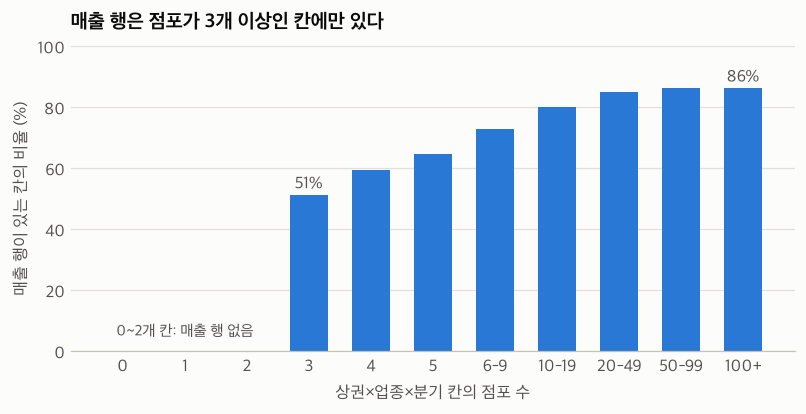

,점포수,매출점포,매출커버리지
업종명,,,
부동산중개업,107155,6333,5.9%
미곡판매,8160,1361,16.7%
자전거 및 기타운송장비,2319,399,17.2%
완구,3413,634,18.6%
가전제품수리,7827,1558,19.9%
애완동물,7359,1636,22.2%


매출커버리지 50% 미만 업종: 62개 중 19개


In [3]:
def trdar_count(df, col):
    return df.loc[df["기준_년분기_코드"].str.startswith("2025"), col].nunique()


coverage = pd.Series({
    "K03 상권 영역": k03["상권코드"].nunique(),
    "K02 점포": k02["상권코드"].nunique(),
    "K04 유동인구": trdar_count(k04_raw, "상권_코드"),
    "K06 직장인구": trdar_count(k06_raw, "상권_코드"),
    "K07 상주인구": trdar_count(k07_raw, "상권_코드"),
    "K05 집객시설": trdar_count(k05_raw, "상권_코드"),
    "K01 추정매출": k01["상권코드"].nunique(),
}, name="상권 수").to_frame()
coverage["전체 대비"] = (coverage["상권 수"] / k03["상권코드"].nunique()).map(pct)
display(coverage)

KEY = ["분기", "상권코드", "업종코드"]
sales_codes = set(k01["업종코드"])
pnl62 = k02[k02["업종코드"].isin(sales_codes)].merge(k01[KEY + ["매출"]], on=KEY, how="left")
pnl62["매출있음"] = pnl62["매출"].notna()

labels = ["0", "1", "2", "3", "4", "5", "6-9", "10-19", "20-49", "50-99", "100+"]
pnl62["점포구간"] = pd.cut(pnl62["점포수"], [-1, 0, 1, 2, 3, 4, 5, 9, 19, 49, 99, np.inf], labels=labels)
by_bin = pnl62.groupby("점포구간", observed=True).agg(칸수=("매출있음", "size"), 매출보유율=("매출있음", "mean"), 점포수=("점포수", "sum"))
display(by_bin.assign(매출보유율=by_bin["매출보유율"].map(pct)))

small = pnl62["점포수"] < 3
print(f"점포 1~2개 칸: 매출 있는 행 {int(pnl62.loc[small, '매출있음'].sum())}개")
print(f"62개 업종 칸 중 점포 3개 미만: 칸 기준 {pct(small.mean())}, 점포 기준 {pct(pnl62.loc[small, '점포수'].sum() / pnl62['점포수'].sum())}")
print(f"62개 업종 점포 중 매출 칸에 속한 비중: {pct(pnl62.loc[pnl62['매출있음'], '점포수'].sum() / pnl62['점포수'].sum())}")
print(f"100개 업종 점포 중 62개 업종 비중: {pct(pnl62['점포수'].sum() / k02['점포수'].sum())}")
print("매출 행의 최소 점포 수:", int(pnl62.loc[pnl62["매출있음"], "점포수"].min()))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(by_bin))
ax.bar(x, by_bin["매출보유율"] * 100, width=0.62, color=PAL["s1"])
ax.set_xticks(x, by_bin.index)
ax.set_ylim(0, 100)
ax.set_xlabel("상권×업종×분기 칸의 점포 수")
ax.set_ylabel("매출 행이 있는 칸의 비율 (%)")
ax.grid(axis="y")
ax.spines["left"].set_visible(False)
for i, v in enumerate(by_bin["매출보유율"] * 100):
    if labels[i] in ("3", "100+"):
        ax.text(i, v + 2, f"{v:.0f}%", ha="center", color=PAL["ink2"])
ax.text(1, 5, "0~2개 칸: 매출 행 없음", ha="center", color=PAL["ink2"], fontsize=10)
ax.set_title("매출 행은 점포가 3개 이상인 칸에만 있다")
save(fig, "01_sales_availability")

low_cov = (pnl62.assign(매출점포=pnl62["점포수"].where(pnl62["매출있음"], 0))
           .groupby("업종명")[["점포수", "매출점포"]].sum())
low_cov["매출커버리지"] = low_cov["매출점포"] / low_cov["점포수"]
display(low_cov.sort_values("매출커버리지").head(6).assign(매출커버리지=lambda d: d["매출커버리지"].map(pct)))
print(f"매출커버리지 50% 미만 업종: 62개 중 {int((low_cov['매출커버리지'] < 0.5).sum())}개")

**결과**

- 점포 1~2개 칸 118,498개에는 매출 행이 **하나도 없습니다.** 매출 행의 최소 점포 수는 정확히 3입니다. 이유를 문서에서 확인하지는 못했고, 소수 점포의 매출이 드러나지 않게 하는 비공개 규칙으로 추정합니다.
- 3개 이상이어도 전부 있는 것은 아닙니다. 점포 3개 칸은 51%, 100개 이상 칸도 86%만 매출 행이 있습니다.
- 62개 업종 칸의 48.8%가 점포 0~2개입니다. 다만 점포 수로는 8.8%입니다. 칸은 많지만 작은 칸들입니다.
- 매출 칸에 속한 점포는 62개 업종 점포의 72.8%입니다. 부동산중개업은 5.9%뿐이고, 62개 중 19개 업종이 50% 미만입니다.

**왜 중요한가**: 매출 행이 없는 칸은 매출이 0인 곳이 아니라 정보가 없는 곳입니다. 경쟁 점포가 거의 없는 입지는 창업 후보로 흥미롭지만, 바로 그 구간에 매출 근거가 없습니다. K01과 K02를 inner join하면 이런 칸이 조용히 사라집니다.

### 1.2 '2025년' 값은 정말 2025년 값인가

**질문**: K05~K07은 "4분기에 연 1회 갱신"이라고 안내되어 있습니다. 실제로 값이 언제 바뀌나요?
**방법**: 모든 값 컬럼을 이어 붙여 상권별로 직전 분기와 완전히 같은지 비교합니다.

직전 분기와 값이 달라진 분기:
  K05 집객시설: []
  K06 직장인구: ['20214', '20224', '20234', '20244']
  K07 상주인구: ['20224', '20234']
부분 변경(0~100% 사이) 분기 수: 0


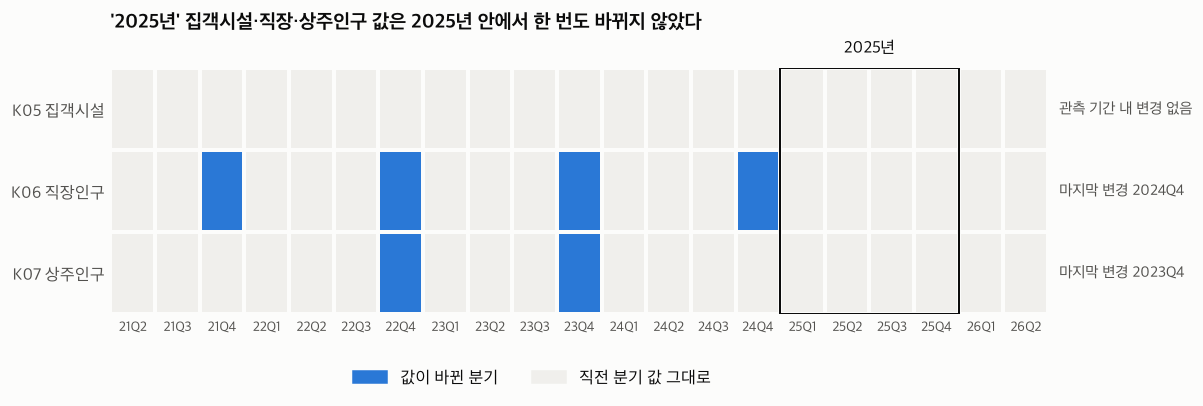

In [4]:
ID_COLS = ["기준_년분기_코드", "상권_구분_코드", "상권_구분_코드_명", "상권_코드", "상권_코드_명"]


def refresh_table(df, name):
    """상권별로 모든 값 컬럼이 직전 분기와 같은 비율을 분기마다 구한다."""
    value_cols = [c for c in df.columns if c not in ID_COLS]
    signature = df[value_cols].fillna("").agg("|".join, axis=1)
    wide = df.assign(sig=signature).pivot(index="상권_코드", columns="기준_년분기_코드", values="sig")
    quarters = sorted(wide.columns)
    rows = []
    for prev, cur in zip(quarters, quarters[1:]):
        both = wide[[prev, cur]].dropna()
        rows.append({"데이터": name, "분기": cur, "유지비율": (both[prev] == both[cur]).mean()})
    return pd.DataFrame(rows)


refresh = pd.concat([
    refresh_table(k05_raw, "K05 집객시설"),
    refresh_table(k06_raw, "K06 직장인구"),
    refresh_table(k07_raw, "K07 상주인구"),
])
grid = refresh.pivot(index="데이터", columns="분기", values="유지비율").loc[["K05 집객시설", "K06 직장인구", "K07 상주인구"]]
changed = grid < 0.5
last_change = {d: (changed.columns[changed.loc[d]].max() if changed.loc[d].any() else None) for d in changed.index}
print("직전 분기와 값이 달라진 분기:")
for d in changed.index:
    print(f"  {d}: {list(changed.columns[changed.loc[d]])}")
print("부분 변경(0~100% 사이) 분기 수:", int(((grid > 0.01) & (grid < 0.99)).sum().sum()))

fig, ax = plt.subplots(figsize=(11, 2.9))
ax.pcolormesh(changed.values[::-1].astype(int), cmap=ListedColormap([PAL["neutral"], PAL["s1"]]), vmin=0, vmax=1,
              edgecolors=PAL["surface"], linewidth=2.5)
qlabels = [f"{q[2:4]}Q{q[4]}" for q in changed.columns]
ax.set_xticks(np.arange(len(qlabels)) + 0.5, qlabels, fontsize=9)
ax.set_yticks(np.arange(3) + 0.5, changed.index[::-1])
ax.spines[["left", "bottom"]].set_visible(False)
y25 = list(changed.columns).index("20251")
ax.add_patch(Rectangle((y25, 0), 4, 3, fill=False, edgecolor=PAL["ink"], linewidth=1.3))
ax.text(y25 + 2, 3.12, "2025년", ha="center", va="bottom", color=PAL["ink"])
for i, d in enumerate(changed.index[::-1]):
    q = last_change[d]
    note = "관측 기간 내 변경 없음" if q is None else f"마지막 변경 {q[:4]}Q{q[4]}"
    ax.text(len(qlabels) + 0.25, i + 0.5, note, va="center", color=PAL["ink2"], fontsize=10)
ax.legend(handles=[Patch(color=PAL["s1"], label="값이 바뀐 분기"), Patch(color=PAL["neutral"], label="직전 분기 값 그대로")],
          loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=2)
ax.set_title("'2025년' 집객시설·직장·상주인구 값은 2025년 안에서 한 번도 바뀌지 않았다", pad=26)
save(fig, "02_refresh_timing")

**결과**

- **K05 집객시설**: 2021Q1부터 2026Q2까지 22개 분기 내내 값이 그대로입니다.
- **K06 직장인구**: 매년 4분기에 바뀌다가 2024Q4가 마지막입니다. 2025Q4에는 바뀌지 않았습니다.
- **K07 상주인구**: 2022Q4와 2023Q4에만 바뀌었습니다. 2024Q4와 2025Q4에는 바뀌지 않았습니다.
- 값은 전체가 한꺼번에 바뀌거나 전혀 안 바뀝니다. 일부만 바뀐 분기는 없습니다.

포털 설명과 다릅니다. 왜 갱신되지 않았는지는 알 수 없고, 값이 바뀌지 않았다는 사실만 확인했습니다. `DATA_HANDOFF.md`는 이 세 데이터를 2025년 자료로 안내하고 있어 팀 공유가 필요합니다.

**왜 중요한가**: 분기 패널에 그대로 붙이면 같은 값이 네 번 반복됩니다. 표본만 4배로 늘고 시간 변화는 0입니다. K01·K02의 2025년 값과 시점도 어긋납니다. 이 노트북에서는 2025Q4 행을 상권별 고정 속성으로 한 번만 씁니다.

### 1.3 상가 좌표를 상권에 붙이기, 그리고 관광특구 겹침

**질문**: S01 상가는 상권 폴리곤에 얼마나 들어가고, 한 상가가 두 상권에 동시에 속하는 경우가 있나요?
**방법**: WGS84 좌표를 EPSG:5181로 바꿔 공간 조인합니다. 인수인계 문서의 예상 키를 처음 실제로 검증하는 단계입니다.

In [5]:
pts = gpd.GeoDataFrame(s01, geometry=gpd.points_from_xy(s01["경도"].astype(float), s01["위도"].astype(float)), crs=4326).to_crs(5181)
joined = gpd.sjoin(pts, k03[["상권코드", "상권구분", "geometry"]], predicate="within", how="left")
inside = joined.dropna(subset=["상권코드"]).copy()
inside["겹침"] = inside["상가업소번호"].duplicated(keep=False)

n_store = s01["상가업소번호"].nunique()
n_outside = int(joined["상권코드"].isna().sum())
print(f"S01 상가 {n_store:,}개 중 어떤 상권에도 안 속함 {n_outside:,}개 ({pct(n_outside / n_store)})")
print(f"두 상권에 동시에 속함 {inside.loc[inside['겹침'], '상가업소번호'].nunique():,}개, 세 상권 이상 {int((inside.groupby('상가업소번호').size() > 2).sum())}개")

overlap = inside.groupby("상권구분")["겹침"].agg(상가수="size", 겹침상가수="sum")
overlap["겹침비율"] = (overlap["겹침상가수"] / overlap["상가수"]).map(pct)
overlap["K01 매출비중"] = (k01.groupby("상권구분")["매출"].sum() / k01["매출"].sum()).map(pct)
q4 = k02[k02["분기"] == "20254"]
overlap["K02 4분기 점포비중"] = (q4.groupby("상권구분")["점포수"].sum() / q4["점포수"].sum()).map(pct)
display(overlap)

total_all = k01["매출"].sum()
k1 = k01[k01["상권구분"] != "관광특구"].copy()
k2 = k02[k02["상권구분"] != "관광특구"].copy()
print(f"서울 매출 합계: 관광특구 포함 {total_all / 1e12:.1f}조원, 제외 {k1['매출'].sum() / 1e12:.1f}조원")

S01 상가 534,978개 중 어떤 상권에도 안 속함 108,931개 (20.4%)


두 상권에 동시에 속함 17,396개, 세 상권 이상 0개


,상가수,겹침상가수,겹침비율,K01 매출비중,K02 4분기 점포비중
상권구분,,,,,
골목상권,154820,415,0.3%,17.3%,33.7%
관광특구,17907,17396,97.1%,6.1%,6.3%
발달상권,228661,12526,5.5%,61.0%,48.4%
전통시장,42055,4455,10.6%,15.6%,11.5%


서울 매출 합계: 관광특구 포함 92.7조원, 제외 87.0조원


**결과**

- 공간 조인은 동작합니다. 다만 상가 534,978개 중 **20.4%(108,931개)는 어떤 상권에도 속하지 않습니다.** 서울 상가 다섯 곳 중 한 곳은 상권 단위 지표로 평가할 수 없습니다.
- 17,396개 상가가 두 상권에 동시에 속합니다. 골목(415)·발달(12,526)·전통시장(4,455)의 겹침을 더하면 17,396으로, 관광특구의 겹침 상가 수와 정확히 같습니다. **겹침은 전부 관광특구와 다른 상권 사이**에서 생깁니다.
- 관광특구 상가의 97.1%가 다른 상권에도 속합니다. 관광특구는 독립된 상권이라기보다 기존 상권을 덮어씌운 묶음에 가깝습니다.

**이후 처리**: 합계와 순위는 관광특구 6개를 뺀 1,644개 상권 기준입니다. 서울 매출 합계가 92.7조원에서 87.0조원으로 줄어듭니다.

### 1.4 개·폐업률과 추정매출 검산

**질문**: 폐업률이 450까지 있는 이유가 뭘까요? 추정매출의 세부 항목은 합계와 맞나요?

In [6]:
pos = k02["점포수"] > 0
close_calc = (k02.loc[pos, "폐업수"] / k02.loc[pos, "점포수"] * 100).round()
open_calc = (k02.loc[pos, "개업수"] / k02.loc[pos, "점포수"] * 100).round()
print(f"공식 '폐업수 / 점포수 x 100' 일치(오차 1 이내): {pct(((close_calc - k02.loc[pos, '폐업률']).abs() <= 1).mean(), 2)}")
print(f"공식 '개업수 / 점포수 x 100' 일치(오차 1 이내): {pct(((open_calc - k02.loc[pos, '개업률']).abs() <= 1).mean(), 2)}")

over100 = k02[(k02["폐업률"] > 100) | (k02["개업률"] > 100)]
print(f"개·폐업률 100 초과 {len(over100)}행, 그 칸의 점포 수 최대 {over100['점포수'].max()}개, 중앙값 {over100['점포수'].median():.0f}개")

zero = k02[k02["점포수"] == 0]
print(f"점포 수 0인 행 {len(zero):,}개, 폐업 {zero['폐업수'].sum():,}건이 있지만 폐업률은 전부 {zero['폐업률'].max()}")
print(f"그 행의 폐업이 전체 폐업에서 차지하는 비중: {pct(zero['폐업수'].sum() / k02['폐업수'].sum())}")

wide = k02.pivot(index=["상권코드", "업종코드"], columns="분기", values=["점포수", "개업수", "폐업수"]).fillna(0)
for a, b in [("20251", "20252"), ("20252", "20253"), ("20253", "20254")]:
    delta = wide["점포수"][b] - wide["점포수"][a]
    flow = wide["개업수"][b] - wide["폐업수"][b]
    print(f"{a}->{b} 점포 증감 = 개업 - 폐업 정확히 일치: {pct((delta == flow).mean())}")

# 추정매출 내부 일관성
times = ["시간대_00~06_매출_금액", "시간대_06~11_매출_금액", "시간대_11~14_매출_금액", "시간대_14~17_매출_금액", "시간대_17~21_매출_금액", "시간대_21~24_매출_금액"]
days = [f"{d}요일_매출_금액" for d in "월화수목금토일"]
ages = ["연령대_10_매출_금액", "연령대_20_매출_금액", "연령대_30_매출_금액", "연령대_40_매출_금액", "연령대_50_매출_금액", "연령대_60_이상_매출_금액"]
ratio = pd.DataFrame({
    "주중+주말": (k01["주중_매출_금액"] + k01["주말_매출_금액"]) / k01["매출"],
    "요일 합": k01[days].sum(axis=1) / k01["매출"],
    "시간대 합": k01[times].sum(axis=1) / k01["매출"],
    "성별 합": (k01["남성_매출_금액"] + k01["여성_매출_금액"]) / k01["매출"],
    "연령대 합": k01[ages].sum(axis=1) / k01["매출"],
}).describe(percentiles=[0.01, 0.5]).T[["min", "1%", "50%", "max"]]
display(ratio)

quarterly = k01.pivot(index=["상권코드", "업종코드"], columns="분기", values="매출")
four = quarterly.dropna()
print(f"4개 분기 매출이 모두 있는 칸 {len(four):,}개 / 전체 {len(quarterly):,}개")
print(f"4개 분기 값이 원 단위까지 똑같은 칸 {int((four.nunique(axis=1) == 1).sum())}개, 2개 이상 분기가 같은 칸 {int((four.nunique(axis=1) < 4).sum())}개")

공식 '폐업수 / 점포수 x 100' 일치(오차 1 이내): 100.00%
공식 '개업수 / 점포수 x 100' 일치(오차 1 이내): 100.00%


개·폐업률 100 초과 149행, 그 칸의 점포 수 최대 4개, 중앙값 1개
점포 수 0인 행 2,197개, 폐업 2,207건이 있지만 폐업률은 전부 0
그 행의 폐업이 전체 폐업에서 차지하는 비중: 4.2%
20251->20252 점포 증감 = 개업 - 폐업 정확히 일치: 99.0%
20252->20253 점포 증감 = 개업 - 폐업 정확히 일치: 98.8%
20253->20254 점포 증감 = 개업 - 폐업 정확히 일치: 99.1%


,min,1%,50%,max
주중+주말,1.00,1.00,1.00,1.00
요일 합,1.00,1.00,1.00,1.00
시간대 합,1.00,1.00,1.00,1.00
성별 합,0.00,0.35,0.99,1.00
연령대 합,0.00,0.35,0.99,1.00


4개 분기 매출이 모두 있는 칸 20,098개 / 전체 22,747개


4개 분기 값이 원 단위까지 똑같은 칸 293개, 2개 이상 분기가 같은 칸 591개


**결과**

- 개·폐업률 공식은 `개·폐업 수 ÷ 전체 점포 수 × 100`을 반올림한 값입니다. 점포가 있는 전 행에서 오차 1 이내로 일치합니다.
- 100 초과 149행은 오류가 아닙니다. 점포가 최대 4개, 중앙값 1개인 칸입니다. 작은 분모에서 생긴 값입니다.
- **함정이 하나 있습니다.** 점포 수가 0인 2,197행에 폐업 2,207건이 있는데 폐업률은 모두 0입니다. 마지막 점포가 문을 닫은 칸이 "폐업률 0"으로 기록됩니다. 전체 폐업의 4.2%입니다. `clsbiz_rt` 컬럼을 평균내지 말고 건수로 다시 계산해야 합니다.
- K02는 내부 일관성이 좋습니다. `점포 증감 = 개업 - 폐업`이 99% 칸에서 정확히 맞습니다.
- K01의 주중·주말, 요일, 시간대 합은 총매출과 일치합니다. 성별·연령 합은 중앙값 0.99이고 최솟값은 0입니다. 포털 FAQ에 따르면 법인 매출에 성별·연령이 없기 때문입니다.
- **293개 칸은 4개 분기 매출이 원 단위까지 똑같습니다.** 2개 분기 이상 같은 칸은 591개입니다. 실제 거래가 이렇게 나올 수는 없으므로 대체값으로 추정합니다. 변동성을 계산하면 이 칸들이 "가장 안정적"으로 나오는 오류가 생깁니다.

### 1.5 두 기관의 점포 수 교차 검증

**질문**: S01을 공간 조인해 센 상가 수와 K02의 점포 수가 맞나요? 2025-12-31 스냅숏을 2025Q4와 같은 시점으로 봐도 되나요?
**방법**: 상권별 합계를 비교하고, 이름이 사실상 같은 9개 업종으로 시범 매핑을 합니다. 공식 연계표는 없습니다.

상권별 Spearman 0.972, K02/S01 합계 비 1.131


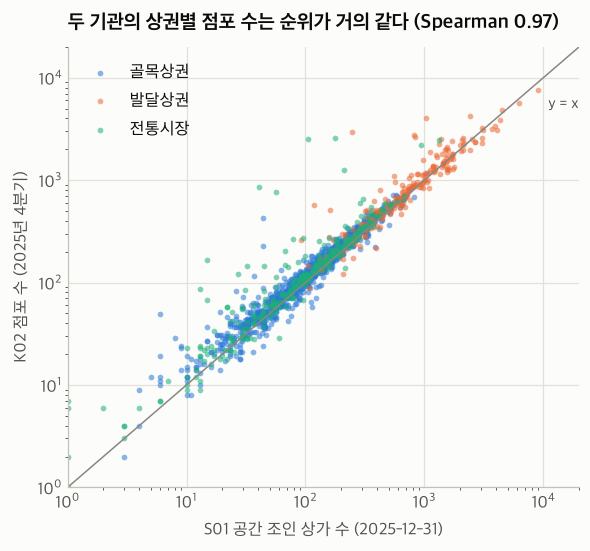

,K02 업종,S01 소분류,K02 점포,S01 상가,K02/S01,상권별 Spearman
0,커피-음료,카페,21413,16843,1.27,0.96
1,미용실,미용실,15815,14848,1.07,0.97
2,편의점,편의점,6291,6759,0.93,0.85
3,치킨전문점,치킨,4147,3698,1.12,0.89
4,부동산중개업,부동산 중개/대리업,25454,17881,1.42,0.94
5,세탁소,세탁소,3835,2420,1.58,0.75
6,슈퍼마켓,슈퍼마켓,8878,5541,1.60,0.78
7,의약품,약국,6775,3944,1.72,0.83
8,일반교습학원,입시·교과학원,14838,10630,1.40,0.85


{'미상': 0.351, '1층': 0.328, '2층 이상': 0.301, '지하': 0.02}


In [7]:
s01_count = inside.groupby("상권코드").size().rename("S01")
k02_count = q4.groupby("상권코드")["점포수"].sum().rename("K02")
compare = pd.concat([s01_count, k02_count], axis=1).fillna(0).join(k03.set_index("상권코드")["상권구분"])
compare_core = compare[compare["상권구분"] != "관광특구"]
rho = stats.spearmanr(compare_core["S01"], compare_core["K02"])[0]
print(f"상권별 Spearman {rho:.3f}, K02/S01 합계 비 {compare_core['K02'].sum() / compare_core['S01'].sum():.3f}")

fig, ax = plt.subplots(figsize=(6, 5.2))
for name, color in TYPE_COLOR.items():
    d = compare_core[compare_core["상권구분"] == name]
    ax.scatter(d["S01"].clip(lower=1), d["K02"].clip(lower=1), s=14, color=color, alpha=0.55, linewidths=0, label=name)
lim = [1, 2e4]
ax.plot(lim, lim, color=PAL["muted"], linewidth=1)
ax.text(11000, 5000, "y = x", color=PAL["ink2"], fontsize=10, ha="left")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("S01 공간 조인 상가 수 (2025-12-31)")
ax.set_ylabel("K02 점포 수 (2025년 4분기)")
ax.grid(True)
ax.legend(loc="upper left")
ax.set_title(f"두 기관의 상권별 점포 수는 순위가 거의 같다 (Spearman {rho:.2f})")
save(fig, "03_store_cross_check")

# 이름이 사실상 같은 업종만 골라 시범 매핑
name_map = {"커피-음료": "카페", "미용실": "미용실", "편의점": "편의점", "치킨전문점": "치킨", "부동산중개업": "부동산 중개/대리업",
            "세탁소": "세탁소", "슈퍼마켓": "슈퍼마켓", "의약품": "약국", "일반교습학원": "입시·교과학원"}
rows = []
core_inside = inside[inside["상권구분"] != "관광특구"]
for k02_name, s01_name in name_map.items():
    a = q4[(q4["업종명"] == k02_name) & (q4["상권구분"] != "관광특구")].groupby("상권코드")["점포수"].sum()
    b = core_inside[core_inside["상권업종소분류명"] == s01_name].groupby("상권코드").size()
    both = pd.concat([a.rename("K02"), b.rename("S01")], axis=1).fillna(0)
    rows.append({"K02 업종": k02_name, "S01 소분류": s01_name, "K02 점포": int(both["K02"].sum()), "S01 상가": int(both["S01"].sum()),
                 "K02/S01": both["K02"].sum() / both["S01"].sum(), "상권별 Spearman": stats.spearmanr(both["K02"], both["S01"])[0]})
map_check = pd.DataFrame(rows)
display(map_check)

floor = s01["층정보"].fillna("미상").map(lambda v: "1층" if v == "1" else ("지하" if v.startswith("지") or v.startswith("B") else ("미상" if v == "미상" else "2층 이상")))
print(floor.value_counts(normalize=True).round(3).to_dict())

**결과**

- 상권별 점포 수의 순위가 거의 같습니다(Spearman 0.97). K02가 합계로 13.1% 더 많습니다. **S01 스냅숏을 2025Q4에 맞추는 것은 큰 문제가 없습니다.**
- 그림에서 대각선 위로 멀리 뜬 점은 대부분 전통시장입니다. K02가 S01보다 훨씬 많이 세는 상권들인데, 시장 안 소규모 점포를 세는 방식의 차이로 추정합니다.
- 업종 단위는 덜 맞습니다. 커피·미용실·부동산은 상권별 순위가 잘 맞지만(0.94~0.97), 세탁소(0.75)와 슈퍼마켓(0.78)은 약합니다. 규모 비는 0.93~1.72입니다. `의약품`과 `약국`처럼 이름이 비슷해도 범위가 다를 수 있습니다.
- S01 층정보는 35.1%가 미상입니다. 1층 여부로 분석하기에는 빈칸이 많습니다.

**제안**: 업종 분석의 기준은 서울 서비스업종 100개로 둡니다. 매출·개폐업이 모두 이 체계이기 때문입니다. S01은 좌표와 세부 업종 확인용으로 씁니다.

## 2. 매출 구조

여기부터 관광특구를 뺍니다. 상권×업종 칸을 연 단위로 묶고, 점포 수는 분기 합 ÷ 4로 평균합니다. K02에 행이 없는 분기는 점포 0개로 봅니다.

### 2.1 분포

상권×업종 칸 76,591개, 매출 있는 칸 22,494개, 4개 분기 모두 있는 칸 19,863개
점포당 월매출(만원): 평균 2,000, 중앙값 723, 상위 1% 18,305, 최대 231,110, 왜도 16.1, log10 왜도 -0.56


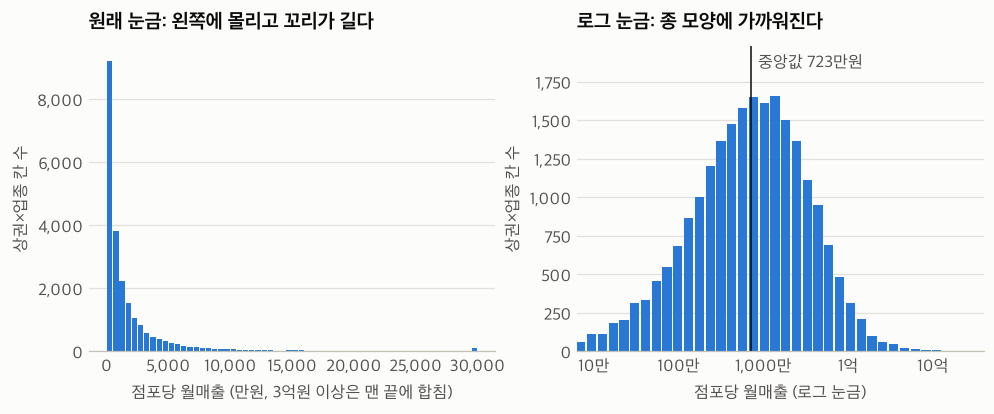

In [8]:
panel = k02.merge(k01[KEY + ["매출", "건수"]], on=KEY, how="left")
panel["점포수_매출분기"] = panel["점포수"].where(panel["매출"].notna())
cell = (panel[panel["상권구분"] != "관광특구"]
        .groupby(["상권코드", "상권명", "상권구분", "업종코드", "업종명", "업종군"], observed=True)
        .agg(점포수합=("점포수", "sum"), 개업수=("개업수", "sum"), 폐업수=("폐업수", "sum"), 프랜차이즈합=("프랜차이즈수", "sum"),
             연매출=("매출", "sum"), 건수=("건수", "sum"), 매출분기수=("매출", "count"), 점포수합_매출=("점포수_매출분기", "sum"))
        .reset_index())
cell["평균점포수"] = cell["점포수합"] / 4
cell = cell[cell["평균점포수"] > 0].copy()
cell["연간폐업률"] = cell["폐업수"] / cell["평균점포수"] * 100
cell["연간개업률"] = cell["개업수"] / cell["평균점포수"] * 100
has_sales = cell["매출분기수"] > 0
cell["점포당월매출"] = (cell["연매출"] / cell["점포수합_매출"] / 3).where(has_sales)
cell = cell.merge(k03[["상권코드", "자치구", "면적_km2"]], on="상권코드", how="left")
cell["밀도"] = cell["평균점포수"] / cell["면적_km2"]
cell["업종내지수"] = cell["점포당월매출"] / cell.groupby("업종코드")["점포당월매출"].transform("median")
sales_cell = cell[cell["매출분기수"] > 0].copy()
print(f"상권×업종 칸 {len(cell):,}개, 매출 있는 칸 {len(sales_cell):,}개, 4개 분기 모두 있는 칸 {int((cell['매출분기수'] == 4).sum()):,}개")

man = sales_cell["점포당월매출"] / 1e4
print(f"점포당 월매출(만원): 평균 {man.mean():,.0f}, 중앙값 {man.median():,.0f}, 상위 1% {man.quantile(0.99):,.0f}, 최대 {man.max():,.0f}, 왜도 {man.skew():.1f}, log10 왜도 {np.log10(man).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].hist(man.clip(upper=30000), bins=60, color=PAL["s1"], rwidth=0.85)
axes[0].set_xlabel("점포당 월매출 (만원, 3억원 이상은 맨 끝에 합침)")
axes[0].set_title("원래 눈금: 왼쪽에 몰리고 꼬리가 길다")
axes[1].hist(np.log10(man), bins=60, color=PAL["s1"], rwidth=0.85)
ticks = [10, 100, 1000, 10000, 100000]
axes[1].set_xticks(np.log10(ticks), ["10만", "100만", "1,000만", "1억", "10억"])
axes[1].set_xlim(0.8, 5.6)
top = axes[1].get_ylim()[1]
axes[1].set_ylim(0, top * 1.14)
axes[1].axvline(np.log10(man.median()), color=PAL["ink"], linewidth=1)
axes[1].text(np.log10(man.median()) + 0.08, top * 1.06, f"중앙값 {man.median():,.0f}만원", color=PAL["ink2"])
axes[1].set_xlabel("점포당 월매출 (로그 눈금)")
axes[1].set_title("로그 눈금: 종 모양에 가까워진다")
axes[0].xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
for ax in axes:
    ax.set_ylabel("상권×업종 칸 수")
    ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y")
    ax.spines["left"].set_visible(False)
save(fig, "04_sales_distribution")

**결과**: 점포당 월매출은 평균 2,000만원, 중앙값 723만원입니다. 평균이 중앙값의 2.8배입니다. 왜도가 16.1에서 로그 변환 후 -0.56으로 줄어듭니다.

**제안**: 평균 대신 중앙값이나 로그값을 씁니다. 점수화할 때도 원값을 min-max로 바꾸면 소수의 극단값이 척도를 차지하므로 백분위나 로그 기준이 안전합니다.

### 2.2 상권 집중도와 상위 상권

계획서 시각화 2번(상권별 추정매출 히트맵)을 포함합니다.

매출 있는 상권 1571개: 상위 1% 24.6%, 상위 10% 65.7%, 하위 50% 4.2%


,상권명,연매출_억,구분,1위 업종,1위 비중
0,노량진역(노량진),"39,048.97",발달상권,수산물판매,90.3%
1,가산디지털단지,"31,009.69",발달상권,일반의류,65.0%
2,용산전자상가(용산역),"24,169.60",발달상권,컴퓨터및주변장치판매,66.3%
3,가락시장,"17,438.39",발달상권,반찬가게,68.1%
4,강남역,"16,452.16",발달상권,일반의원,31.6%
5,종로3가역,"12,692.84",발달상권,시계및귀금속,54.7%
6,잠실역,"12,409.47",발달상권,일반의류,59.5%
7,청량리청과물시장,"7,952.81",전통시장,청과상,93.6%
8,청량리종합시장,"7,729.09",전통시장,청과상,87.8%
9,여의도역(여의도),"7,674.63",발달상권,한식음식점,29.7%


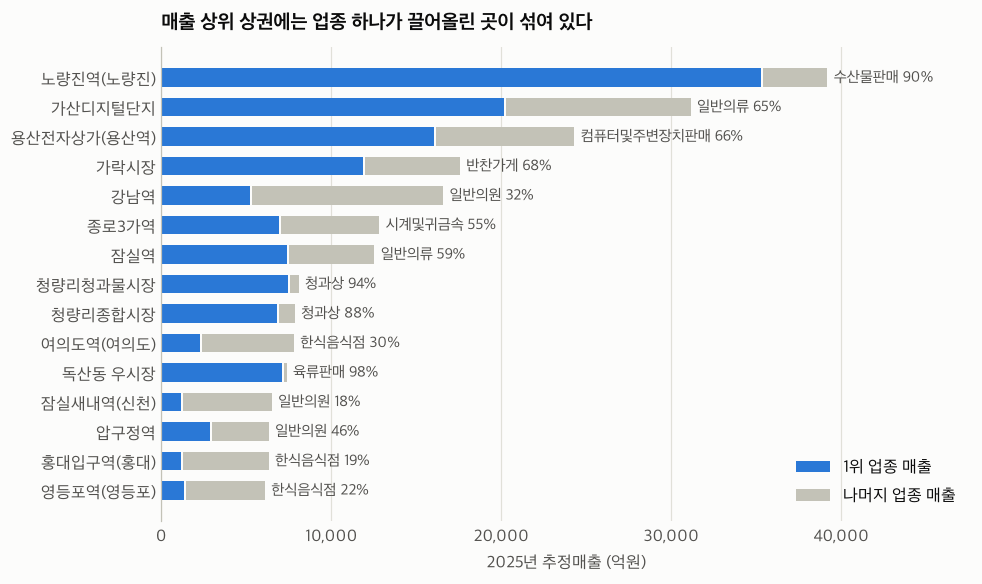

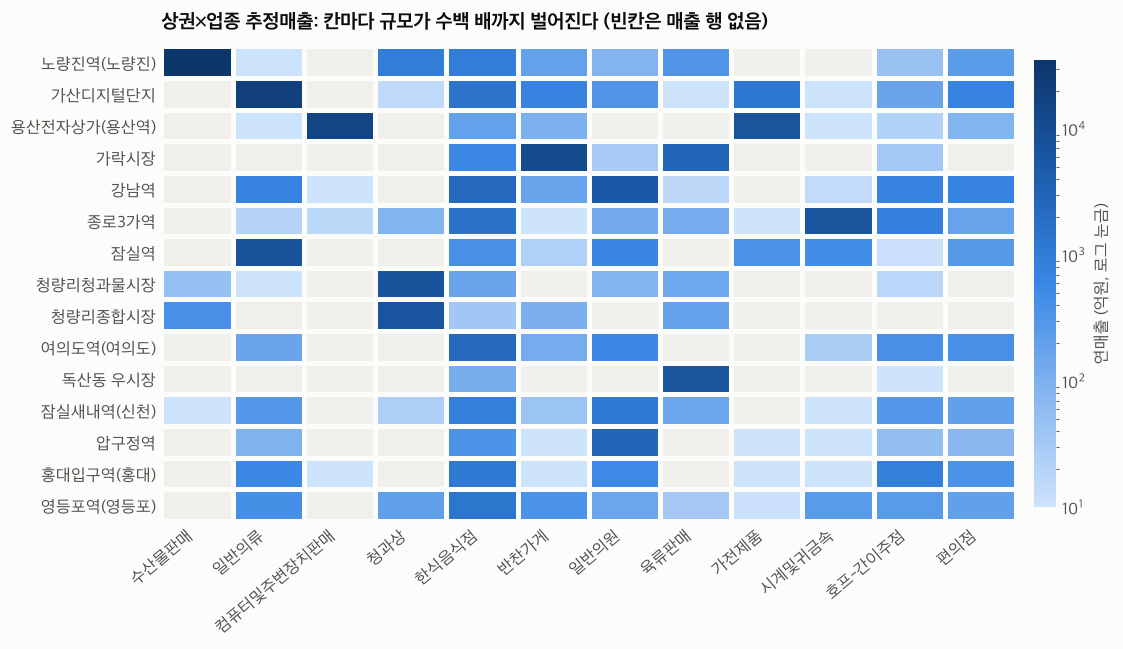

In [9]:
by_trdar = k1.groupby("상권코드")["매출"].sum().sort_values(ascending=False)
n_t = len(by_trdar)
share_top = lambda p: by_trdar.head(int(np.ceil(n_t * p))).sum() / by_trdar.sum()
print(f"매출 있는 상권 {n_t}개: 상위 1% {pct(share_top(0.01))}, 상위 10% {pct(share_top(0.10))}, 하위 50% {pct(by_trdar.tail(n_t // 2).sum() / by_trdar.sum())}")

names = k03.set_index("상권코드")["상권명"]
top_ind = (k1.groupby(["상권코드", "업종명"])["매출"].sum().rename("업종매출").reset_index()
           .sort_values("업종매출", ascending=False).drop_duplicates("상권코드").set_index("상권코드"))
top15 = pd.DataFrame({"상권명": names.reindex(by_trdar.head(15).index), "연매출_억": by_trdar.head(15) / 1e8})
top15["구분"] = k03.set_index("상권코드")["상권구분"].reindex(top15.index)
top15["1위 업종"] = top_ind["업종명"].reindex(top15.index)
top15["1위 비중"] = top_ind["업종매출"].reindex(top15.index) / by_trdar.reindex(top15.index)
display(top15.assign(**{"1위 비중": top15["1위 비중"].map(pct)}).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9.5, 5.6))
d = top15.iloc[::-1]
main = d["연매출_억"] * d["1위 비중"]
y = np.arange(len(d))
ax.barh(y, main, height=0.62, color=PAL["s1"], label="1위 업종 매출")
ax.barh(y, d["연매출_억"] - main, left=main + 120, height=0.62, color=PAL["axis"], label="나머지 업종 매출")
ax.set_yticks(y, d["상권명"].str.slice(0, 16))
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["연매출_억"] + 500, i, f"{r['1위 업종']} {r['1위 비중'] * 100:.0f}%", va="center", color=PAL["ink2"], fontsize=10)
ax.set_xlabel("2025년 추정매출 (억원)")
ax.set_xlim(0, d["연매출_억"].max() * 1.22)
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x")
ax.spines["bottom"].set_visible(False)
ax.legend(loc="lower right")
ax.set_title("매출 상위 상권에는 업종 하나가 끌어올린 곳이 섞여 있다")
save(fig, "05_top_trdar")

hot_ind = k1[k1["상권코드"].isin(top15.index)].groupby("업종명")["매출"].sum().nlargest(12).index
hot = (k1[k1["상권코드"].isin(top15.index) & k1["업종명"].isin(hot_ind)]
       .pivot_table(index="상권코드", columns="업종명", values="매출", aggfunc="sum")
       .reindex(index=top15.index, columns=hot_ind) / 1e8)
fig, ax = plt.subplots(figsize=(10.5, 5.6))
mesh = ax.pcolormesh(hot.values[::-1], cmap=BLUES, norm=LogNorm(vmin=10, vmax=hot.max().max()), edgecolors=PAL["surface"], linewidth=2)
ax.set_xticks(np.arange(hot.shape[1]) + 0.5, hot.columns, rotation=40, ha="right")
ax.set_yticks(np.arange(hot.shape[0]) + 0.5, top15["상권명"].str.slice(0, 16).values[::-1])
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_facecolor(PAL["neutral"])
cb = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("연매출 (억원, 로그 눈금)")
ax.set_title("상권×업종 추정매출: 칸마다 규모가 수백 배까지 벌어진다 (빈칸은 매출 행 없음)")
save(fig, "06_trdar_industry_heatmap")

**결과**

- 매출은 소수 상권에 몰려 있습니다. 1,571개 상권 중 상위 1%(16개)가 24.6%, 상위 10%가 65.7%, 하위 50%는 4.2%입니다.
- 상위 15개 중 9곳은 업종 하나가 50%를 넘습니다. 노량진역 수산물 90%, 청량리청과물시장 청과상 94%, 독산동 우시장 육류 98%입니다.
- 가락시장의 1위 업종은 반찬가게(68%)입니다. 도매시장 매출이 어떤 업종으로 분류되는지 확인이 필요합니다.
- 강남역, 홍대입구역, 영등포역처럼 1위 업종 비중이 낮은 곳이 상대적으로 업종이 고른 상권입니다.

**제안**: "노량진역이 매출 1위"는 창업 입지 정보가 아닙니다. 한식당을 내려는 사람에게 수산시장 매출은 의미가 없습니다. 상권 총매출을 점수에 넣지 말고 희망 업종 안에서 비교합니다.

### 2.3 업종별 매출

전체 업종 표는 `tables/industry_summary.csv`에 저장합니다. 미식별 비중은 총매출 중 성별이 없는 몫으로, 법인 매출의 대리 지표입니다.

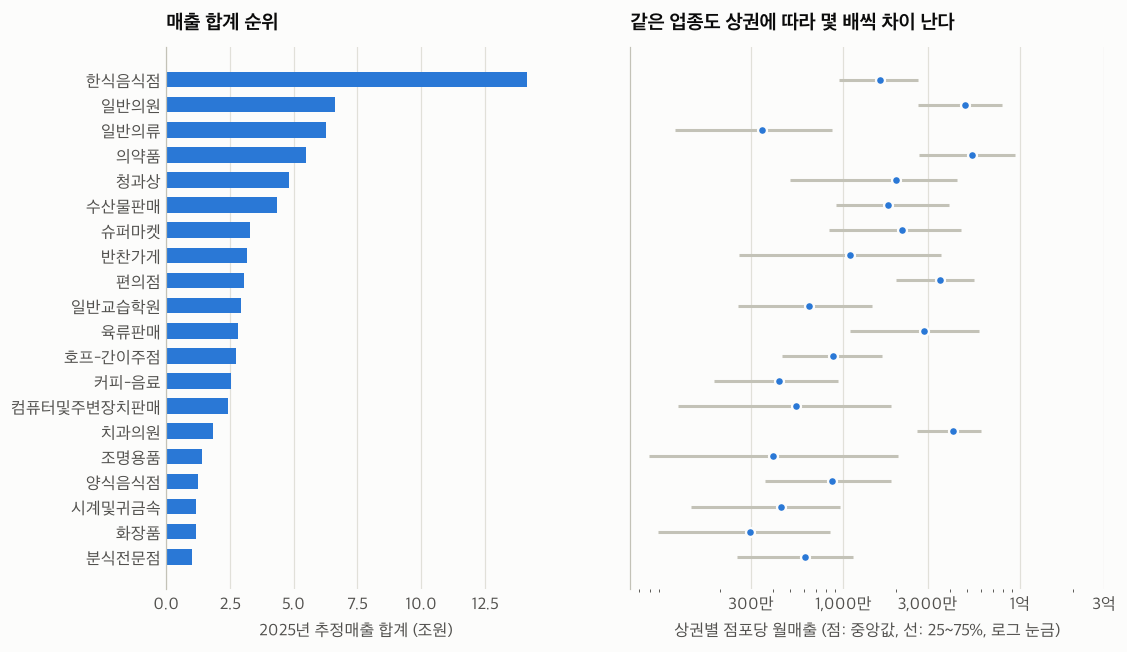

,업종명,전체매출비중,월매출_중앙값,미식별비중,건당매출_만원,매출커버리지
0,한식음식점,16.29,"1,607.10",21.24,3.93,99.22
1,일반의원,7.62,"4,894.37",0.24,5.28,91.44
2,일반의류,7.22,347.25,2.82,6.91,90.15
3,의약품,6.29,"5,376.75",5.32,2.48,84.96
4,청과상,5.54,"1,998.03",7.25,2.72,45.29
5,수산물판매,5.01,"1,779.67",13.30,6.52,45.35
6,슈퍼마켓,3.79,"2,151.13",5.21,1.13,86.62
7,반찬가게,3.62,"1,090.36",16.38,2.46,65.59
8,편의점,3.50,"3,520.34",2.92,0.71,84.87
9,일반교습학원,3.37,635.70,0.54,31.16,83.70


미식별(법인 추정) 비중 상위


,업종명,전체매출비중,월매출_중앙값,미식별비중,건당매출_만원,매출커버리지
0,문구,0.91,687.09,49.24,3.23,62.75
1,컴퓨터및주변장치판매,2.78,541.01,43.01,12.79,57.95
2,자동차미용,0.02,333.33,33.77,9.40,26.45
3,화초,0.22,209.54,31.64,4.53,63.92
4,철물점,0.08,293.43,30.22,3.65,42.85
5,여관,0.24,370.49,28.35,5.41,74.65
6,일식음식점,1.15,"1,110.35",25.02,4.25,79.36
7,조명용품,1.61,398.59,24.63,12.40,63.42


In [10]:
ind = (cell.groupby(["업종코드", "업종명", "업종군"], observed=True)
       .agg(평균점포수=("평균점포수", "sum"), 개업수=("개업수", "sum"), 폐업수=("폐업수", "sum"), 프랜차이즈합=("프랜차이즈합", "sum"), 점포수합=("점포수합", "sum"),
            상권수=("상권코드", "nunique"), 밀도중앙값=("밀도", "median"))
       .reset_index().set_index("업종코드"))
ind["연간폐업률"] = ind["폐업수"] / ind["평균점포수"] * 100
ind["연간개업률"] = ind["개업수"] / ind["평균점포수"] * 100
ind["프랜차이즈비중"] = ind["프랜차이즈합"] / ind["점포수합"] * 100

agg_sales = k1.groupby("업종코드").agg(연매출=("매출", "sum"), 건수=("건수", "sum"), 남=("남성_매출_금액", "sum"), 여=("여성_매출_금액", "sum"))
ind = ind.join(agg_sales)
ind["미식별비중"] = (1 - (ind["남"] + ind["여"]) / ind["연매출"]) * 100
ind["건당매출_만원"] = ind["연매출"] / ind["건수"] / 1e4
q = sales_cell.groupby("업종코드")["점포당월매출"].quantile([0.25, 0.5, 0.75]).unstack() / 1e4
q.columns = ["월매출_p25", "월매출_중앙값", "월매출_p75"]
ind = ind.join(q)
ind["매출커버리지"] = sales_cell.groupby("업종코드")["점포수합"].sum() / ind["점포수합"] * 100
ind["전체매출비중"] = ind["연매출"] / ind["연매출"].sum() * 100
ind.drop(columns=["프랜차이즈합", "점포수합", "남", "여"]).sort_values("연매출", ascending=False).round(2).to_csv(TAB / "industry_summary.csv", encoding="utf-8-sig")

top20 = ind.nlargest(20, "연매출").iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 6.4), sharey=True, gridspec_kw={"width_ratios": [1, 1.25]})
y = np.arange(len(top20))
axes[0].barh(y, top20["연매출"] / 1e12, height=0.62, color=PAL["s1"])
axes[0].set_yticks(y, top20["업종명"])
axes[0].set_xlabel("2025년 추정매출 합계 (조원)")
axes[0].set_title("매출 합계 순위")
axes[0].grid(axis="x")
axes[0].spines["bottom"].set_visible(False)
axes[1].hlines(y, top20["월매출_p25"], top20["월매출_p75"], color=PAL["axis"], linewidth=2)
axes[1].scatter(top20["월매출_중앙값"], y, s=34, color=PAL["s1"], zorder=3, edgecolor=PAL["surface"], linewidth=1.5)
axes[1].set_xscale("log")
axes[1].set_xticks([300, 1000, 3000, 10000, 30000], ["300만", "1,000만", "3,000만", "1억", "3억"])
axes[1].set_xlabel("상권별 점포당 월매출 (점: 중앙값, 선: 25~75%, 로그 눈금)")
axes[1].set_title("같은 업종도 상권에 따라 몇 배씩 차이 난다")
axes[1].grid(axis="x")
axes[1].spines["bottom"].set_visible(False)
save(fig, "07_industry_sales")

show = ["업종명", "전체매출비중", "월매출_중앙값", "미식별비중", "건당매출_만원", "매출커버리지"]
display(ind.nlargest(12, "연매출")[show].reset_index(drop=True))
print("미식별(법인 추정) 비중 상위")
display(ind.dropna(subset=["연매출"]).nlargest(8, "미식별비중")[show].reset_index(drop=True))

**결과**

- 합계 1위는 한식음식점(16.3%)입니다. 일반의류는 합계 3위지만 점포당 월매출 중앙값이 347만원으로 20개 업종 중 최하위권입니다. 합계가 큰 것과 점포 하나가 버는 것은 다른 이야기입니다.
- 같은 업종도 상권에 따라 차이가 큽니다. 조명용품, 화장품, 반찬가게처럼 범위가 넓은 업종은 입지 선택의 영향이 큰 후보입니다.
- 청과상과 수산물판매는 매출 칸에 속한 점포가 45%입니다. 이 업종의 합계는 점포 절반 이하를 근거로 합니다.
- 미식별 비중은 문구 49%, 컴퓨터및주변장치판매 43%로 높습니다. 기업 고객 비중이 큰 업종으로 보입니다. 한식음식점도 21%입니다.

### 2.4 분기 흐름

,서비스,소매,외식,합계
분기,,,,
20251,4.04,11.05,5.97,21.06
20252,3.95,10.92,6.34,21.21
20253,4.15,11.31,6.35,21.81
20254,4.09,12.24,6.56,22.89


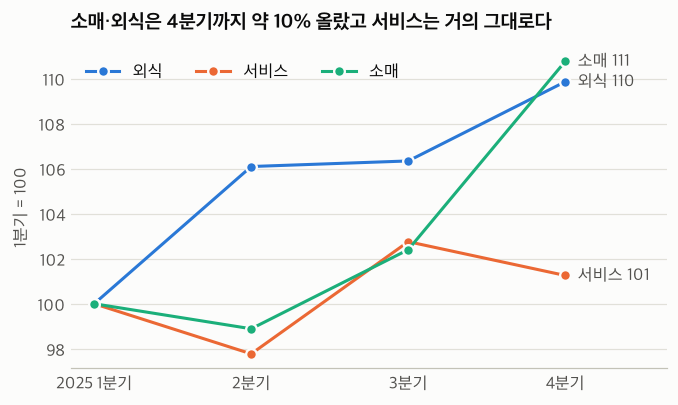

4분기/1분기 하위: {'자전거 및 기타운송장비': 0.79, '외국어학원': 0.81, '골프연습장': 0.84, '전자상거래업': 0.85, '스포츠 강습': 0.87}
4분기/1분기 상위: {'철물점': 1.31, '섬유제품': 1.34, '신발': 1.37, '애완동물': 1.55, '인테리어': 1.64}


In [11]:
qt = k1.groupby(["분기", "업종군"])["매출"].sum().unstack()
idx = qt / qt.iloc[0] * 100
display(pd.concat([(qt / 1e12).round(2), (k1.groupby("분기")["매출"].sum() / 1e12).rename("합계").round(2)], axis=1))

fig, ax = plt.subplots(figsize=(7, 3.8))
for name in ["외식", "서비스", "소매"]:
    ax.plot(idx.index, idx[name], color=GROUP_COLOR[name], linewidth=2, marker="o", markersize=7, markeredgecolor=PAL["surface"], markeredgewidth=1.5, label=name)
    ax.text(3.08, idx[name].iloc[-1], f"{name} {idx[name].iloc[-1]:.0f}", va="center", color=PAL["ink2"])
ax.set_xticks(range(4), ["2025 1분기", "2분기", "3분기", "4분기"])
ax.set_xlim(-0.15, 3.65)
ax.set_ylabel("1분기 = 100")
ax.grid(axis="y")
ax.spines["left"].set_visible(False)
ax.legend(loc="upper left", ncol=3)
ax.set_title("소매·외식은 4분기까지 약 10% 올랐고 서비스는 거의 그대로다")
save(fig, "08_quarterly_index")

ratio_q = (k1[k1["분기"] == "20254"].groupby("업종명")["매출"].sum() / k1[k1["분기"] == "20251"].groupby("업종명")["매출"].sum()).sort_values()
print("4분기/1분기 하위:", ratio_q.head(5).round(2).to_dict())
print("4분기/1분기 상위:", ratio_q.tail(5).round(2).to_dict())

**결과**: 1분기를 100으로 보면 4분기에 소매 111, 외식 110, 서비스 101입니다. 외식은 2분기에, 소매는 4분기에 오릅니다. 업종별로는 인테리어 1.64배, 애완동물 1.55배가 크게 올랐고 자전거 0.79배, 외국어학원 0.81배는 줄었습니다.

**주의**: 1년치 네 점이라 계절성인지 추세인지 구분할 수 없습니다. 계획서의 "분기별 매출 변동성"은 이 자료만으로 안정성 지표로 쓰기 어렵습니다.

## 3. 소비 패턴

업종별로 언제, 누가 쓰는지 봅니다. 연령은 결제자 기준이고 성별·연령이 식별된 매출만 포함합니다. 숫자는 업종별 최댓값입니다.

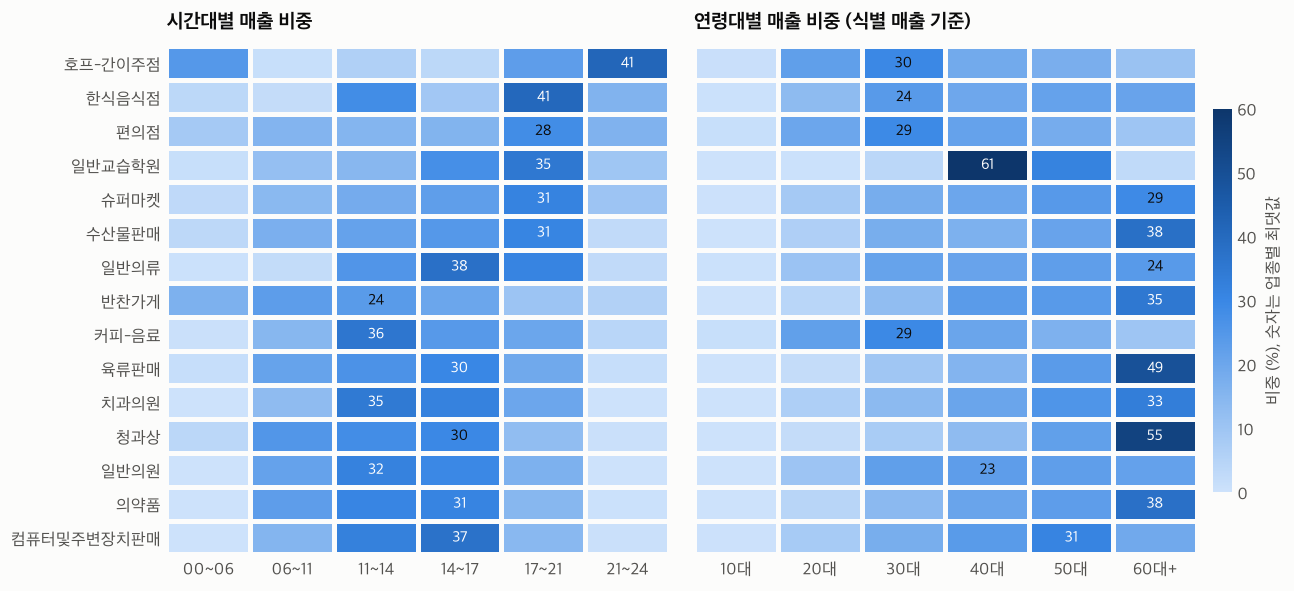

외식 업종의 상권구분별 매출 구성 (%)


,점심 11~14,저녁 17~21,심야 21~06,주말,20·30대,50대 이상
상권구분,,,,,,
골목상권,25.59,38.21,20.81,29.82,35.44,44.05
발달상권,28.38,33.81,22.90,25.31,46.03,32.45
전통시장,20.74,38.87,24.50,30.83,37.29,43.36


In [12]:
top15_ind = ind.nlargest(15, "연매출")["업종명"]
base = k1[k1["업종명"].isin(top15_ind)].groupby("업종명")[times + ages + ["주말_매출_금액", "매출"]].sum()
share_time = base[times].div(base[times].sum(axis=1), axis=0) * 100
share_age = base[ages].div(base[ages].sum(axis=1), axis=0) * 100
order = share_time[["시간대_17~21_매출_금액", "시간대_21~24_매출_금액", "시간대_00~06_매출_금액"]].sum(axis=1).sort_values().index
share_time, share_age = share_time.loc[order], share_age.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, data, xlabels, title in [
    (axes[0], share_time, ["00~06", "06~11", "11~14", "14~17", "17~21", "21~24"], "시간대별 매출 비중"),
    (axes[1], share_age, ["10대", "20대", "30대", "40대", "50대", "60대+"], "연령대별 매출 비중 (식별 매출 기준)"),
]:
    mesh = ax.pcolormesh(data.values, cmap=BLUES, vmin=0, vmax=60, edgecolors=PAL["surface"], linewidth=2)
    ax.set_xticks(np.arange(6) + 0.5, xlabels)
    ax.set_yticks(np.arange(len(order)) + 0.5, order)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_title(title)
    for i, row in enumerate(data.values):
        j = row.argmax()
        ax.text(j + 0.5, i + 0.5, f"{row[j]:.0f}", ha="center", va="center", color="#ffffff" if row[j] > 30 else PAL["ink"], fontsize=10)
cb = fig.colorbar(mesh, ax=axes, fraction=0.018, pad=0.015)
cb.outline.set_visible(False)
cb.set_label("비중 (%), 숫자는 업종별 최댓값")
save(fig, "09_time_age_profile")

food = k1[k1["업종군"] == "외식"].groupby("상권구분")[times + ages + ["주말_매출_금액", "여성_매출_금액", "남성_매출_금액", "매출"]].sum()
profile = pd.DataFrame({
    "점심 11~14": food["시간대_11~14_매출_금액"] / food["매출"] * 100,
    "저녁 17~21": food["시간대_17~21_매출_금액"] / food["매출"] * 100,
    "심야 21~06": (food["시간대_21~24_매출_금액"] + food["시간대_00~06_매출_금액"]) / food["매출"] * 100,
    "주말": food["주말_매출_금액"] / food["매출"] * 100,
    "20·30대": food[["연령대_20_매출_금액", "연령대_30_매출_금액"]].sum(axis=1) / food[ages].sum(axis=1) * 100,
    "50대 이상": food[["연령대_50_매출_금액", "연령대_60_이상_매출_금액"]].sum(axis=1) / food[ages].sum(axis=1) * 100,
})
print("외식 업종의 상권구분별 매출 구성 (%)")
display(profile)

**결과**

- 시간대가 업종 성격을 잘 가릅니다. 호프 21~24시 41%, 한식 17~21시 41%, 커피 11~14시 36%, 의원은 낮 시간대입니다.
- 일반교습학원은 40대가 61%입니다. 수강생이 아니라 결제자인 학부모로 보입니다. 청과상(60대 이상 55%)과 육류판매(49%)는 고령층 비중이 높습니다.
- 외식만 놓고 상권 유형을 비교하면 발달상권은 20·30대 46.0%, 주말 25.3%입니다. 골목상권은 50대 이상 44.1%, 주말 29.8%입니다. 발달상권이 평일 직장·젊은 층 수요에 더 기대고 골목상권은 동네 수요에 가깝다고 볼 수 있습니다.

**쓰임**: 희망 업종이 정해지면 그 업종의 고객층과 상권의 고객층이 맞는지 보는 "수요 적합성" 변수로 쓸 수 있습니다. K01 안에 필요한 값이 모두 있습니다.

## 4. 점포 변화

### 4.1 개업과 폐업

연간 비율은 4개 분기 건수 합 ÷ 평균 점포 수입니다. 계획서 시각화 3번(업종별 점포 밀집도)과 프랜차이즈 비중도 여기서 정리합니다.

,점포수,개업,폐업,순증
분기,,,,
20251,487655,8461,14180,-5719
20252,485303,10118,12095,-1977
20253,483281,10674,12443,-1769
20254,481196,8941,10878,-1937


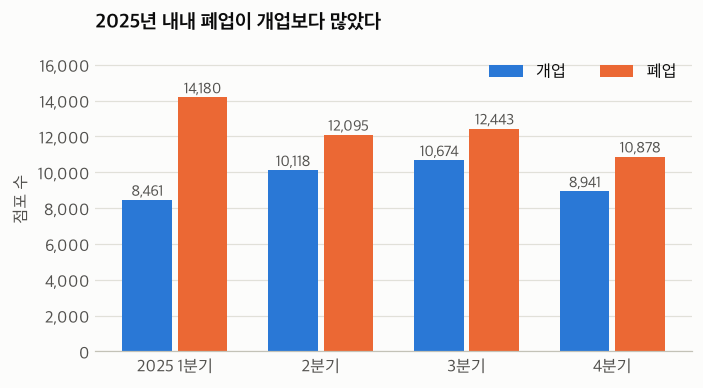

전체 연간 폐업률 10.1%, 개업률 7.9%
연중 점포가 0인 칸을 빼면서 빠진 폐업: 588건 / 49,596건


,업종명,연간폐업률,연간개업률,평균점포수
0,전자상거래업,20.24,0.57,"11,500.25"
1,PC방,18.56,4.50,"1,110.00"
2,패스트푸드점,17.45,12.65,"4,946.75"
3,호프-간이주점,16.74,9.33,"14,089.50"
4,치킨전문점,16.64,13.95,"4,206.50"
5,분식전문점,16.47,13.35,"9,215.25"


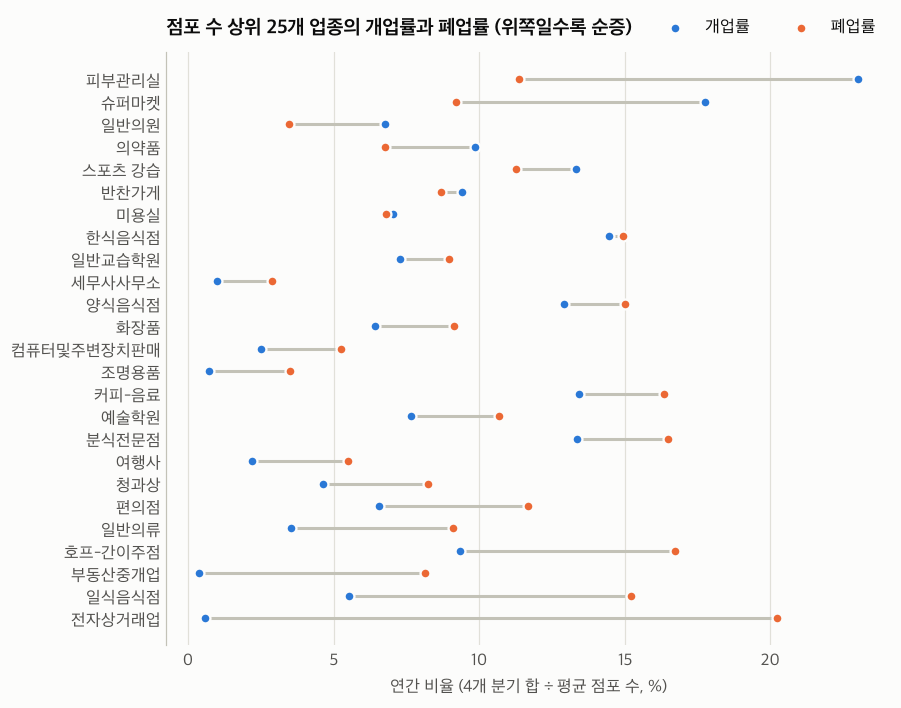

,업종명,프랜차이즈비중,평균점포수
0,편의점,73.22,"6,441.25"
1,치킨전문점,62.01,"4,206.50"
2,패스트푸드점,52.81,"4,946.75"
3,슈퍼마켓,28.58,"8,581.75"
4,안경,26.74,"2,139.75"
5,커피-음료,25.17,"21,640.25"
6,제과점,24.06,"5,383.75"
7,분식전문점,22.96,"9,215.25"
8,세탁소,14.68,"3,812.75"
9,기타오락장,14.65,"1,013.75"


밀도 상위 (상권 내 km²당 점포 수 중앙값)


,업종명,밀도중앙값,상권수
0,한식음식점,228.62,1569
1,부동산중개업,124.96,1537
2,커피-음료,102.54,1522
3,미용실,100.37,1471
4,일반의류,84.87,1489
5,호프-간이주점,64.95,1323
6,전자상거래업,62.50,1406
7,일반교습학원,62.15,1340


In [13]:
flow = k2.groupby("분기").agg(점포수=("점포수", "sum"), 개업=("개업수", "sum"), 폐업=("폐업수", "sum"))
flow["순증"] = flow["개업"] - flow["폐업"]
display(flow)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(4)
ax.bar(x - 0.19, flow["개업"], width=0.34, color=PAL["s1"], label="개업")
ax.bar(x + 0.19, flow["폐업"], width=0.34, color=PAL["s2"], label="폐업")
for i, (o, c) in enumerate(zip(flow["개업"], flow["폐업"])):
    ax.text(i - 0.19, o + 200, f"{o:,}", ha="center", color=PAL["ink2"], fontsize=10)
    ax.text(i + 0.19, c + 200, f"{c:,}", ha="center", color=PAL["ink2"], fontsize=10)
ax.set_xticks(x, ["2025 1분기", "2분기", "3분기", "4분기"])
ax.set_ylabel("점포 수")
ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y")
ax.spines["left"].set_visible(False)
ax.legend(loc="upper right", ncol=2)
ax.set_ylim(0, flow["폐업"].max() * 1.2)
ax.set_title("2025년 내내 폐업이 개업보다 많았다")
save(fig, "10_open_close_flow")

top25 = ind.nlargest(25, "평균점포수").copy()
top25["순증률"] = top25["연간개업률"] - top25["연간폐업률"]
top25 = top25.sort_values("순증률")
all_close = ind["폐업수"].sum() / ind["평균점포수"].sum() * 100
all_open = ind["개업수"].sum() / ind["평균점포수"].sum() * 100
print(f"전체 연간 폐업률 {all_close:.1f}%, 개업률 {all_open:.1f}%")
print(f"연중 점포가 0인 칸을 빼면서 빠진 폐업: {int(k2['폐업수'].sum() - ind['폐업수'].sum())}건 / {int(k2['폐업수'].sum()):,}건")
display(ind.nlargest(6, "연간폐업률")[["업종명", "연간폐업률", "연간개업률", "평균점포수"]].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(top25))
ax.hlines(y, top25["연간개업률"], top25["연간폐업률"], color=PAL["axis"], linewidth=2)
ax.scatter(top25["연간개업률"], y, s=42, color=PAL["s1"], zorder=3, edgecolor=PAL["surface"], linewidth=1.5, label="개업률")
ax.scatter(top25["연간폐업률"], y, s=42, color=PAL["s2"], zorder=3, edgecolor=PAL["surface"], linewidth=1.5, label="폐업률")
ax.set_yticks(y, top25["업종명"])
ax.set_xlabel("연간 비율 (4개 분기 합 ÷ 평균 점포 수, %)")
ax.grid(axis="x")
ax.spines["bottom"].set_visible(False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title("점포 수 상위 25개 업종의 개업률과 폐업률 (위쪽일수록 순증)")
save(fig, "11_industry_open_close")

display(ind.nlargest(10, "프랜차이즈비중")[["업종명", "프랜차이즈비중", "평균점포수"]].reset_index(drop=True))
print("밀도 상위 (상권 내 km²당 점포 수 중앙값)")
display(ind.nlargest(8, "밀도중앙값")[["업종명", "밀도중앙값", "상권수"]].reset_index(drop=True))

**결과**

- 관광특구를 뺀 2025년 개업은 38,194건, 폐업은 49,596건으로 11,402개가 순감했습니다. 네 분기 모두 폐업이 더 많습니다. 1분기 순감(-5,719)이 가장 큽니다.
- 연간 폐업률 10.1%, 개업률 7.9%입니다. 연중 점포가 0인 칸을 빼면서 폐업 588건(1.2%)이 제외됐고, 포함해도 폐업률은 0.1%포인트 정도만 달라집니다.
- 외식 업종은 들고 나는 폭이 큽니다. 커피-음료는 개업 13.4%, 폐업 16.3%입니다. 호프-간이주점은 폐업 16.7%에 개업 9.3%로 순감 폭이 큽니다. 피부관리실과 슈퍼마켓은 순증입니다.
- **전자상거래업은 이상합니다.** 폐업 20.2%인데 개업은 0.6%입니다. 축소 추정 상위권도 이 업종이 차지합니다. 사업자 주소지 기준으로 잡힌 것으로 보이며 점포 입지와 관련이 약해 추천 대상에서 빼는 것을 제안합니다.
- 프랜차이즈 비중은 편의점 73%, 치킨 62%, 패스트푸드 53%로 업종 차이가 큽니다. 이 업종들은 개인 창업과 가맹 창업을 나눠 볼 필요가 있습니다.
- 상권 면적당 점포 수 중앙값은 한식 229개/km², 부동산중개업 125개, 커피 103개, 미용실 100개입니다.

### 4.2 작은 칸의 폐업률 문제와 축소 추정

**질문**: 칸별 폐업률을 그대로 순위 매겨도 되나요?
**방법**: 점포 수와 폐업률을 함께 그립니다(깔때기 그림). 우연만으로 생기는 흔들림이 얼마나 큰지 봅니다.

축소 추정은 칸의 값을 업종 평균 쪽으로 당기는 방법입니다. 점포가 적을수록 많이 당깁니다.

`축소 폐업률 = (폐업 수 + α) / (평균 점포 수 + α / 업종 폐업률)`

α는 데이터에서 추정합니다(포아송-감마 모형의 적률 추정).

alpha = 13.19, 사전 점포 수(중앙값) = 162.1개
점포 5개 미만 칸 비율 72.9%, 그중 폐업 0건 83.8%
폐업률 표준편차: 점포 5개 미만 51.0, 50개 이상 7.0


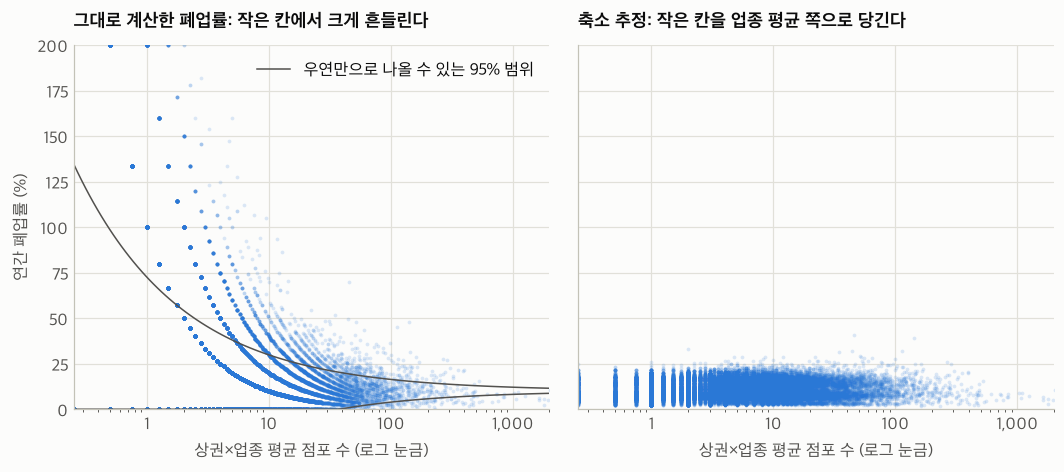

그대로 계산한 폐업률 상위 5


,상권명,업종명,평균점포수,폐업수,연간폐업률,축소폐업률
0,노원 을지대학교병원,전자상거래업,0.25,3,"1,200.00",24.75
1,홍대부속여중고앞,일식음식점,0.25,3,"1,200.00",18.63
2,송파나루역 2번,일반교습학원,0.25,3,"1,200.00",11.00
3,광진초등학교,화초,0.25,2,800.00,9.25
4,수유동우체국,애완동물,0.25,2,800.00,15.10


축소폐업률 상위 5


,상권명,업종명,평균점포수,폐업수,연간폐업률,축소폐업률
0,포이초등학교(개포목련어린이공원),전자상거래업,45.75,32,69.95,40.75
1,굽은다리역,전자상거래업,141.50,68,48.06,39.29
2,염창무학아파트,전자상거래업,2.00,9,450.00,33.04
3,서교동(홍대),전자상거래업,44.50,22,49.44,32.09
4,언주역(차병원),한식음식점,112.50,51,45.33,31.97


축소 전후 상위 100칸 겹침: 2


In [14]:
rate_cell = cell.copy()
p_all = rate_cell["폐업수"].sum() / rate_cell["평균점포수"].sum()
mu = rate_cell["평균점포수"] * rate_cell.groupby("업종코드")["폐업수"].transform("sum") / rate_cell.groupby("업종코드")["평균점포수"].transform("sum")
p_ind = mu / rate_cell["평균점포수"]
alpha = (mu ** 2).sum() / ((rate_cell["폐업수"] - mu) ** 2 - mu).sum()
rate_cell["축소폐업률"] = (rate_cell["폐업수"] + alpha) / (rate_cell["평균점포수"] + alpha / p_ind) * 100
pseudo = (alpha / p_ind).median()
print(f"alpha = {alpha:.2f}, 사전 점포 수(중앙값) = {pseudo:.1f}개")

tiny = rate_cell["평균점포수"] < 5
big = rate_cell["평균점포수"] >= 50
print(f"점포 5개 미만 칸 비율 {pct(tiny.mean())}, 그중 폐업 0건 {pct((rate_cell.loc[tiny, '폐업수'] == 0).mean())}")
print(f"폐업률 표준편차: 점포 5개 미만 {rate_cell.loc[tiny, '연간폐업률'].std():.1f}, 50개 이상 {rate_cell.loc[big, '연간폐업률'].std():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True, gridspec_kw={"wspace": 0.06})
for ax, col, title in [(axes[0], "연간폐업률", "그대로 계산한 폐업률: 작은 칸에서 크게 흔들린다"), (axes[1], "축소폐업률", "축소 추정: 작은 칸을 업종 평균 쪽으로 당긴다")]:
    ax.scatter(rate_cell["평균점포수"], rate_cell[col], s=6, color=PAL["s1"], alpha=0.16, linewidths=0, rasterized=True)
    ax.set_xscale("log")
    ax.set_xlim(0.25, 2000)
    ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
    ax.set_xlabel("상권×업종 평균 점포 수 (로그 눈금)")
    ax.grid(True)
    ax.set_title(title, fontsize=12)
nn = np.logspace(np.log10(0.25), np.log10(2000), 120)
axes[0].plot(nn, 100 * (p_all + 1.96 * np.sqrt(p_all / nn)), color=PAL["ink2"], linewidth=1, label="우연만으로 나올 수 있는 95% 범위")
axes[0].plot(nn, 100 * np.clip(p_all - 1.96 * np.sqrt(p_all / nn), 0, None), color=PAL["ink2"], linewidth=1)
axes[0].legend(loc="upper right")
axes[0].set_ylabel("연간 폐업률 (%)")
axes[0].set_ylim(0, 200)
save(fig, "12_closure_funnel")

cols = ["상권명", "업종명", "평균점포수", "폐업수", "연간폐업률", "축소폐업률"]
print("그대로 계산한 폐업률 상위 5")
display(rate_cell.nlargest(5, "연간폐업률")[cols].reset_index(drop=True))
print("축소폐업률 상위 5")
display(rate_cell.nlargest(5, "축소폐업률")[cols].reset_index(drop=True))
print("축소 전후 상위 100칸 겹침:", len(set(rate_cell.nlargest(100, "연간폐업률").index) & set(rate_cell.nlargest(100, "축소폐업률").index)))

**결과**

- 칸의 72.9%가 점포 5개 미만이고, 그중 83.8%는 폐업이 0건입니다. 나머지는 폐업 한 건만 나와도 비율이 크게 뜁니다. 폐업률 표준편차가 점포 5개 미만에서 51.0, 50개 이상에서 7.0입니다.
- 원값 상위권은 평균 점포 0.25개 칸입니다. 한 분기만 점포가 있던 곳으로 폐업률 1,200%가 나옵니다.
- α = 13.19입니다. 업종 폐업률로 환산하면 점포 약 160개 분량의 사전 정보입니다. 즉 점포가 160개쯤 되어야 칸 자체의 값과 업종 평균을 반반 믿는다는 뜻입니다. 대부분의 칸은 업종 평균에 가깝게 당겨집니다.
- **원값 상위 100칸과 축소 추정 상위 100칸 중 겹치는 칸은 2개뿐입니다.** 원값 순위는 거의 우연입니다.

**제안**: 폐업률을 쓸 때는 건수로 다시 계산하고 축소 추정을 적용합니다.

## 5. 점수 설계 전에 확인한 관계

STEP 4는 매출 잠재력, 경쟁 위험, 안정성, 수요를 점수로 만들 계획입니다. 각 점수의 방향과 신뢰도를 데이터로 먼저 확인합니다.

### 5.1 상권 유형 비교: 업종 구성을 보정해도 차이가 남나

상권 유형마다 업종 구성이 다르므로 원값 비교는 왜곡될 수 있습니다. 업종 내 지수로 다시 비교합니다.

In [15]:
mix = sales_cell.groupby("상권구분").agg(
    칸수=("업종내지수", "size"),
    점포당월매출_중앙값_만원=("점포당월매출", lambda s: s.median() / 1e4),
    업종내지수_중앙값=("업종내지수", "median"),
)
mix["점포가중_월매출_만원"] = sales_cell.groupby("상권구분")["연매출"].sum() / sales_cell.groupby("상권구분")["점포수합_매출"].sum() / 3 / 1e4
display(mix)

mix_share = cell.groupby(["상권구분", "업종군"], observed=True)["평균점포수"].sum().unstack()
display((mix_share.div(mix_share.sum(axis=1), axis=0) * 100).round(1))

,칸수,점포당월매출_중앙값_만원,업종내지수_중앙값,점포가중_월매출_만원
상권구분,,,,
골목상권,11569,520.50,0.78,"1,479.40"
발달상권,7612,"1,023.78",1.33,"2,694.47"
전통시장,3313,965.02,1.22,"2,951.30"


업종군,서비스,소매,외식
상권구분,,,
골목상권,38.20,34.20,27.60
발달상권,35.70,38.60,25.70
전통시장,19.00,56.80,24.20


**결과**: 점포당 월매출 중앙값은 골목상권 521만원, 발달상권 1,024만원, 전통시장 965만원입니다. 업종 내 지수로 보정해도 0.78, 1.33, 1.22로 순서가 같습니다. 전통시장은 소매가 56.8%로 업종 구성이 크게 다르지만 차이는 구성 때문만은 아닙니다.

매출 칸에 속한 칸만 비교한 값입니다. 골목상권의 작은 칸이 많이 빠져 있으므로 실제 차이는 이와 다를 수 있습니다.

### 5.2 수요 지표: 규모와 효율을 나눠 보기

**질문**: 유동인구가 많은 상권이 장사가 잘되나요?
**방법**: 상권 단위로 지표를 모아 Spearman 상관을 구합니다. 연매출은 규모 지표이고, 업종을 보정한 매출 지수는 효율 지표입니다. 인구는 2025년 유동인구 평균, 직장·상주·집객시설은 2025Q4 행을 쓰며 1.2의 시점 문제를 그대로 갖고 있습니다. 상권별 표는 `tables/trdar_summary.csv`에 있습니다.

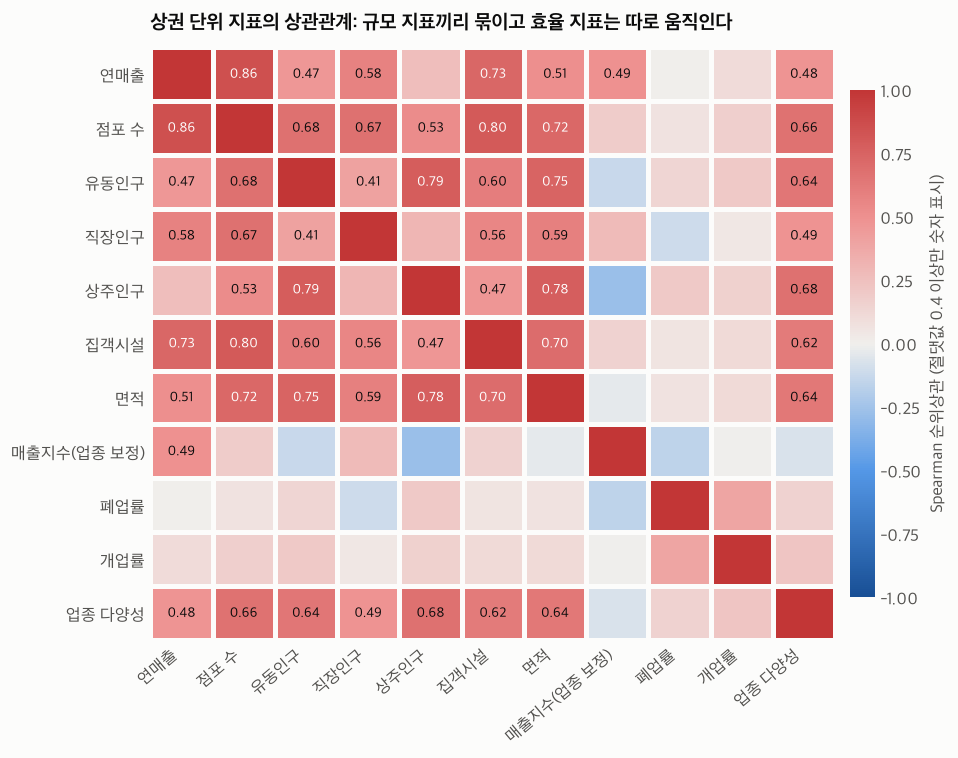

,연매출,매출지수(업종 보정),폐업률
연매출,1.00,0.49,0.00
점포 수,0.86,0.18,0.06
유동인구,0.47,-0.13,0.14
직장인구,0.58,0.27,-0.11
상주인구,0.26,-0.28,0.20
집객시설,0.73,0.15,0.06
면적,0.51,-0.04,0.07
매출지수(업종 보정),0.49,1.00,-0.16
폐업률,0.00,-0.16,1.00
개업률,0.11,-0.00,0.40


매출지수와 수요 밀도(면적당)의 Spearman 상관


,전체,골목상권,발달상권,전통시장
유동밀도,-0.15,-0.17,-0.15,0.03
직장밀도,0.40,0.26,0.25,0.31
상주밀도,-0.40,-0.27,-0.45,-0.21


상권당 평균 집객시설 수


상권구분,골목상권,발달상권,전통시장
버스_정거장_수,3.17,9.27,1.38
약국_수,1.22,7.47,1.72
은행_수,0.21,4.65,0.42
관공서_수,0.58,1.57,0.23
지하철_역_수,0.05,0.78,0.05
숙박_시설_수,0.15,0.43,0.18
일반_병원_수,0.06,0.40,0.03
슈퍼마켓_수,0.05,0.11,0.25


In [16]:
num_cols = ["총_유동인구_수"]
k04 = k04_raw.assign(유동인구=pd.to_numeric(k04_raw["총_유동인구_수"]))
flow_mean = k04.groupby("상권_코드")["유동인구"].mean().rename("유동인구")
k05q = k05_raw[k05_raw["기준_년분기_코드"] == "20254"].set_index("상권_코드")
k06q = k06_raw[k06_raw["기준_년분기_코드"] == "20254"].set_index("상권_코드")
k07q = k07_raw[k07_raw["기준_년분기_코드"] == "20254"].set_index("상권_코드")

trdar_sum = k2.groupby("상권코드").agg(점포수합=("점포수", "sum"), 개업수=("개업수", "sum"), 폐업수=("폐업수", "sum"), 프랜차이즈=("프랜차이즈수", "sum"))
trdar_sum["평균점포수"] = trdar_sum["점포수합"] / 4
trdar_sum["연간폐업률"] = trdar_sum["폐업수"] / trdar_sum["평균점포수"] * 100
trdar_sum["연간개업률"] = trdar_sum["개업수"] / trdar_sum["평균점포수"] * 100
trdar_sum["프랜차이즈비중"] = trdar_sum["프랜차이즈"] / trdar_sum["점포수합"] * 100

ix = sales_cell.assign(w=sales_cell["평균점포수"], l=np.log(sales_cell["업종내지수"]))
trdar_sum["매출지수"] = np.exp(ix.groupby("상권코드").apply(lambda d: np.average(d["l"], weights=d["w"]), include_groups=False))
trdar_sum["연매출"] = k1.groupby("상권코드")["매출"].sum()

share = cell.groupby("상권코드").apply(lambda d: d["평균점포수"] / d["평균점포수"].sum(), include_groups=False)
trdar_sum["업종다양성"] = (-share * np.log(share)).groupby(level=0).sum()

tr = k03.drop(columns=["geometry"]).set_index("상권코드")[["상권명", "상권구분", "자치구", "면적_km2"]].join(trdar_sum, how="inner")
tr = tr.join(flow_mean)
tr["직장인구"] = pd.to_numeric(k06q["총_직장_인구_수"]).reindex(tr.index)
tr["상주인구"] = pd.to_numeric(k07q["총_상주인구_수"]).reindex(tr.index)
tr["집객시설"] = pd.to_numeric(k05q["집객시설_수"]).reindex(tr.index)
tr["점포밀도"] = tr["평균점포수"] / tr["면적_km2"]
tr = tr[tr["상권구분"] != "관광특구"]
tr.drop(columns=["점포수합", "프랜차이즈"]).round(3).to_csv(TAB / "trdar_summary.csv", encoding="utf-8-sig")

corr_cols = {"연매출": "연매출", "평균점포수": "점포 수", "유동인구": "유동인구", "직장인구": "직장인구", "상주인구": "상주인구", "집객시설": "집객시설",
             "면적_km2": "면적", "매출지수": "매출지수(업종 보정)", "연간폐업률": "폐업률", "연간개업률": "개업률", "업종다양성": "업종 다양성"}
corr = tr[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
n = len(corr)
mesh = ax.pcolormesh(corr.values[::-1], cmap=DIVERGE, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1), edgecolors=PAL["surface"], linewidth=2)
ax.set_xticks(np.arange(n) + 0.5, corr.columns, rotation=40, ha="right")
ax.set_yticks(np.arange(n) + 0.5, corr.index[::-1])
ax.spines[["left", "bottom"]].set_visible(False)
for i in range(n):
    for j in range(n):
        v = corr.values[::-1][i, j]
        if abs(v) >= 0.4 and n - 1 - i != j:
            ax.text(j + 0.5, i + 0.5, f"{v:.2f}", ha="center", va="center", fontsize=9, color="#ffffff" if abs(v) > 0.7 else PAL["ink"])
cb = fig.colorbar(mesh, ax=ax, fraction=0.035, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("Spearman 순위상관 (절댓값 0.4 이상만 숫자 표시)")
ax.set_title("상권 단위 지표의 상관관계: 규모 지표끼리 묶이고 효율 지표는 따로 움직인다")
save(fig, "13_correlation")
display(corr[["연매출", "매출지수(업종 보정)", "폐업률"]].round(2))

density = tr.assign(유동밀도=tr["유동인구"] / tr["면적_km2"], 직장밀도=tr["직장인구"] / tr["면적_km2"], 상주밀도=tr["상주인구"] / tr["면적_km2"])
rows = {"전체": density}
rows.update({name: d for name, d in density.groupby("상권구분")})
density_corr = pd.DataFrame({name: d[["매출지수", "유동밀도", "직장밀도", "상주밀도"]].corr(method="spearman")["매출지수"].drop("매출지수") for name, d in rows.items()})
print("매출지수와 수요 밀도(면적당)의 Spearman 상관")
display(density_corr.round(2))

fac = [c for c in k05_raw.columns if c.endswith("_수") and c != "집객시설_수"]
fac_q = k05q[fac].apply(pd.to_numeric).fillna(0)
fac_q["상권구분"] = k03.set_index("상권코드")["상권구분"].reindex(fac_q.index)
fac_view = fac_q[fac_q["상권구분"] != "관광특구"].groupby("상권구분")[fac].mean().T
fac_view = fac_view.loc[fac_view.sum(axis=1).sort_values(ascending=False).index].head(8)
print("상권당 평균 집객시설 수")
display(fac_view.round(2))

**결과**

- 연매출, 점포 수, 유동인구, 직장인구, 집객시설, 면적은 서로 0.41~0.86으로 함께 움직입니다. 모두 "상권이 크다"는 같은 정보를 담고 있습니다. 이 지표들을 따로 점수에 넣으면 규모를 여러 번 세게 됩니다.
- 효율을 나타내는 매출 지수는 규모와 다르게 움직입니다. 유동인구 **-0.13**, 직장인구 **+0.27**, 상주인구 **-0.28**입니다.
- 면적당 밀도로 바꿔도 유동 -0.15, 직장 +0.40, 상주 -0.40으로 방향이 같습니다. 골목·발달·전통시장 안에서 따로 봐도 직장은 양(+0.25~0.31), 상주는 음(-0.21~-0.45)입니다. 유동은 -0.17~+0.03으로 약합니다.
- 폐업률은 연매출(0.00)이나 규모 지표와 거의 관계가 없습니다.
- 집객시설은 발달상권이 상권당 버스정거장 9.3, 약국 7.5, 은행 4.7개로 골목상권(3.2, 1.2, 0.2개)보다 많습니다. 다만 1.2에서 봤듯 값이 고정되어 있습니다.
- K05 공백은 `DATA_HANDOFF.md`의 Open API 대조 내용에 따라 0으로 봤습니다. `집객시설_수`는 하위 시설 합과 달라 정의가 아직 불명확합니다. 상관 분석에는 원값을 그대로 썼습니다.

**주의**: 추정매출은 카드사 자료를 기반으로 합니다. 법인카드나 직장인 결제가 많은 상권이 높게 잡힐 수 있어 직장인구와의 상관이 일부 부풀려졌을 가능성이 있습니다. 유동인구의 집계 기준(일 평균인지 분기 합계인지)은 문서에서 확인하지 못해 상권 간 상대 비교로만 씁니다.

### 5.3 같은 업종 점포가 많으면 점포당 매출이 낮아지나

**질문**: "경쟁 위험" 점수는 같은 업종 점포가 많을수록 나쁘다고 가정합니다. 데이터도 그런가요?

**방법**: 4개 분기 매출이 모두 있는 칸으로 회귀합니다.

`log(칸 매출) = β × log(같은 업종 점포 수) + 유동·직장·상주·면적 + 상권 유형 + 업종`

β가 **탄력성**입니다. 점포 수가 1% 많을 때 칸 매출이 β% 많다는 뜻입니다.

- β = 1: 점포가 늘어난 만큼 매출도 늘어 점포당 매출이 같습니다.
- β < 1: 매출을 나눠 갖습니다. 경쟁 가정과 맞습니다.
- β > 1: 점포가 많은 칸의 점포당 매출이 더 높습니다.

점포당 매출을 종속변수로 쓰면 분모에 점포 수가 들어가 음의 관계가 저절로 생기므로 칸 매출을 씁니다. 표준오차는 상권 단위로 묶어 계산합니다.

회귀 표본 19,757칸, 상권 1534개, 업종 62개


R^2 = 0.594


,계수,하한,상한
같은 업종 점포 수,1.19,1.15,1.22
유동인구,-0.07,-0.11,-0.03
직장인구,0.08,0.06,0.11
상주인구,-0.07,-0.10,-0.04
상권 면적,-0.09,-0.16,-0.03


칸 300개 이상 업종 29개, beta 범위 0.73 ~ 1.48, 1 미만(95% 상한 기준) 1개


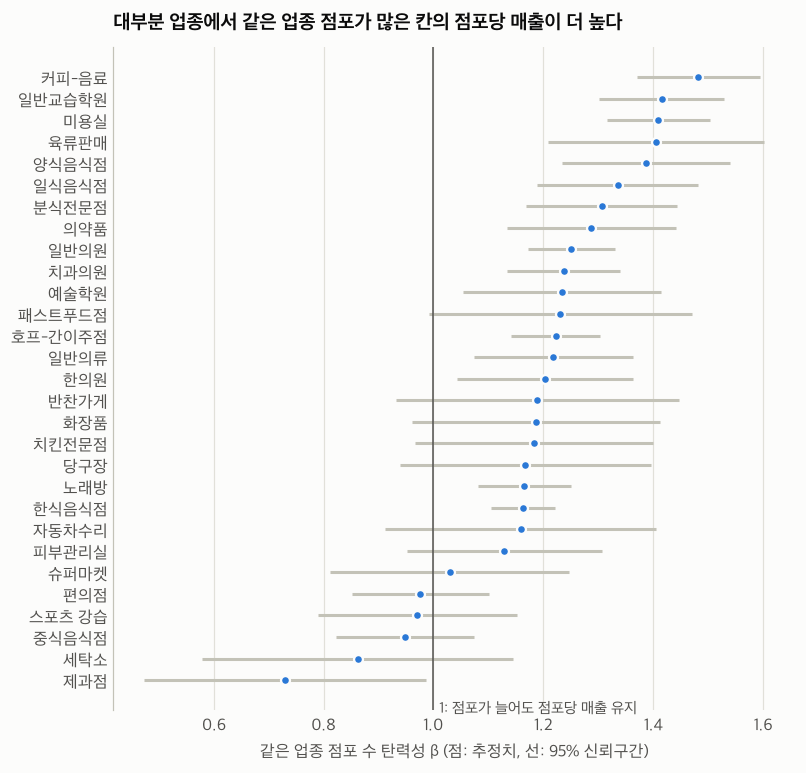

,업종명,칸수,beta,하한,상한,유동인구,직장인구,상주인구,spearman_점포당
0,제과점,390,0.73,0.47,0.99,-0.15,0.12,-0.14,-0.09
1,세탁소,402,0.86,0.58,1.14,0.08,0.15,-0.13,-0.10
2,중식음식점,412,0.95,0.82,1.07,0.06,0.25,-0.11,0.07
3,스포츠 강습,434,0.97,0.79,1.15,-0.03,0.16,-0.10,0.01
4,편의점,649,0.98,0.85,1.10,0.17,0.07,-0.11,0.14
5,슈퍼마켓,826,1.03,0.81,1.25,-0.18,-0.00,0.10,-0.08
6,피부관리실,334,1.13,0.95,1.31,-0.05,0.32,-0.16,0.11
7,자동차수리,356,1.16,0.91,1.41,-0.22,0.10,0.05,0.11
8,한식음식점,1379,1.16,1.10,1.22,-0.03,0.18,-0.08,0.27
9,노래방,492,1.17,1.08,1.25,-0.00,0.12,-0.05,0.23


In [17]:
reg = cell[cell["매출분기수"] == 4].merge(tr[["유동인구", "직장인구", "상주인구"]].reset_index(), on="상권코드")
reg = reg.dropna(subset=["유동인구", "직장인구", "상주인구"]).copy()
reg = reg[reg["유동인구"] > 0]
reg = reg.assign(
    ln_sales=np.log(reg["연매출"]), ln_store=np.log(reg["평균점포수"]), ln_flow=np.log(reg["유동인구"]),
    ln_work=np.log1p(reg["직장인구"]), ln_home=np.log1p(reg["상주인구"]), ln_area=np.log(reg["면적_km2"]),
    trdar_type=reg["상권구분"].astype(str), industry=reg["업종코드"].astype(str),
    group_id=reg["상권코드"].astype("category").cat.codes,
)
print(f"회귀 표본 {len(reg):,}칸, 상권 {reg['상권코드'].nunique()}개, 업종 {reg['업종코드'].nunique()}개")

fit = smf.ols("ln_sales ~ ln_store + ln_flow + ln_work + ln_home + ln_area + C(trdar_type) + C(industry)", data=reg).fit(
    cov_type="cluster", cov_kwds={"groups": reg["group_id"]})
terms = {"ln_store": "같은 업종 점포 수", "ln_flow": "유동인구", "ln_work": "직장인구", "ln_home": "상주인구", "ln_area": "상권 면적"}
coef = pd.DataFrame({"계수": fit.params[list(terms)], "하한": fit.conf_int()[0][list(terms)], "상한": fit.conf_int()[1][list(terms)]}).rename(index=terms)
print(f"R^2 = {fit.rsquared:.3f}")
display(coef)

rows = []
for code, d in reg.groupby("업종코드"):
    if len(d) < 300:
        continue
    f = smf.ols("ln_sales ~ ln_store + ln_flow + ln_work + ln_home + ln_area", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["group_id"]})
    lo, hi = f.conf_int().loc["ln_store"]
    rows.append({"업종명": d["업종명"].iloc[0], "칸수": len(d), "beta": f.params["ln_store"], "하한": lo, "상한": hi,
                 "유동인구": f.params["ln_flow"], "직장인구": f.params["ln_work"], "상주인구": f.params["ln_home"],
                 "spearman_점포당": stats.spearmanr(d["평균점포수"], d["점포당월매출"])[0]})
forest = pd.DataFrame(rows).sort_values("beta")
print(f"칸 300개 이상 업종 {len(forest)}개, beta 범위 {forest['beta'].min():.2f} ~ {forest['beta'].max():.2f}, 1 미만(95% 상한 기준) {int((forest['상한'] < 1).sum())}개")

fig, ax = plt.subplots(figsize=(8, max(4.5, len(forest) * 0.27)))
y = np.arange(len(forest))
ax.hlines(y, forest["하한"], forest["상한"], color=PAL["axis"], linewidth=2)
ax.scatter(forest["beta"], y, s=34, color=PAL["s1"], zorder=3, edgecolor=PAL["surface"], linewidth=1.5)
ax.axvline(1, color=PAL["ink2"], linewidth=1)
ax.text(1.01, -0.9, "1: 점포가 늘어도 점포당 매출 유지", color=PAL["ink2"], fontsize=10, va="top")
ax.set_yticks(y, forest["업종명"])
ax.set_xlabel("같은 업종 점포 수 탄력성 β (점: 추정치, 선: 95% 신뢰구간)")
ax.grid(axis="x")
ax.spines["bottom"].set_visible(False)
ax.set_title("대부분 업종에서 같은 업종 점포가 많은 칸의 점포당 매출이 더 높다")
save(fig, "14_competition_elasticity")
display(forest.round(2).reset_index(drop=True))

위 회귀는 관측한 인구만 통제합니다. 상권 고유의 수요를 통째로 고정하기 위해 **상권과 업종의 고정효과**를 넣어 다시 확인합니다. 같은 상권 안에서 업종끼리 비교하는 방식입니다.

In [18]:
def two_way_demean(df, cols, a, b, n_iter=60):
    """상권 평균과 업종 평균을 번갈아 빼서 두 고정효과를 제거한다."""
    X = df[cols].astype(float).copy()
    for _ in range(n_iter):
        X = X - X.groupby(df[a]).transform("mean")
        X = X - X.groupby(df[b]).transform("mean")
    return X


rows = []
for label, sub in [("전체", reg), ("점포 5개 이상", reg[reg["평균점포수"] >= 5]), ("점포 10개 이상", reg[reg["평균점포수"] >= 10])]:
    within = two_way_demean(sub, ["ln_sales", "ln_store"], "상권코드", "업종코드")
    f = smf.ols("ln_sales ~ ln_store - 1", data=within).fit(cov_type="cluster", cov_kwds={"groups": sub["group_id"]})
    lo, hi = f.conf_int().loc["ln_store"]
    rows.append({"표본": label, "칸수": len(sub), "beta": f.params["ln_store"], "하한": lo, "상한": hi})
display(pd.DataFrame(rows).round(3))
print(f"beta 추정치가 1보다 큰 업종 {int((forest['beta'] > 1).sum())}/{len(forest)}개, 95% 하한까지 1보다 큰 업종 {int((forest['하한'] > 1).sum())}개")

,표본,칸수,beta,하한,상한
0,전체,19757,1.19,1.15,1.23
1,점포 5개 이상,13865,1.29,1.24,1.33
2,점포 10개 이상,7082,1.33,1.26,1.40


beta 추정치가 1보다 큰 업종 24/29개, 95% 하한까지 1보다 큰 업종 16개


**결과**

- 전체 β는 1.19(95% 구간 1.15~1.22)입니다. 29개 업종 중 24개에서 1보다 크고, 16개는 95% 하한까지 1보다 큽니다. 구간 전체가 1 아래인 업종은 제과점(0.73)뿐입니다.
- 상권과 업종을 고정해도 1.19이고, 점포 10개 이상 칸만 보면 1.33입니다. 상권 전체에 공통인 수요 때문만은 아니라는 뜻입니다. 특정 상권의 특정 업종에만 있는 수요는 여전히 통제되지 않습니다.
- 커피-음료(1.48), 미용실(1.41), 일반교습학원(1.42)은 높고 세탁소, 중식, 편의점은 1 근처입니다.

**해석**: 같은 업종이 많은 칸이 매출을 나눠 갖는 모습은 이 데이터에서 보이지 않습니다. 그러나 **점포를 더 내면 매출이 오른다는 뜻은 아닙니다.** 장사가 되는 곳에 점포가 몰린다는 반대 방향으로도 똑같이 설명됩니다. 점포 3개 미만 칸이 빠져 있고 추정매출이 점포 수를 활용해 산출됐을 가능성도 배제하지 못합니다.

**제안**: 점포 수를 그대로 감점하지 않습니다. 경쟁 위험은 수요 대비 점포 수나 최근 점포 증가 속도처럼 "수요보다 공급이 빨리 느는지"를 보는 지표로 설계하고, 후자는 2024년 자료가 있어야 계산할 수 있습니다.

### 5.4 매출과 경쟁이 폐업을 설명하나

**방법**: 업종 안에서 점포당 매출과 점포 수를 각각 5등분해 폐업률을 비교합니다. 이어서 포아송 회귀로 업종·상권 유형을 함께 통제합니다. 포아송 회귀는 건수를 다루는 회귀이며 결과를 "폐업률이 몇 배인가"로 읽습니다.

,폐업,개업,점포,폐업률,개업률,오차
매출5분위,,,,,,
1,4212,3335,"39,206.75",10.74,8.51,0.32
2,5314,4225,"48,266.00",11.01,8.75,0.30
3,5844,4943,"52,843.75",11.06,9.35,0.28
4,7730,6679,"71,742.00",10.77,9.31,0.24
5,8882,7597,"85,346.25",10.41,8.90,0.22


,폐업,개업,점포,폐업률,개업률,오차
경쟁5분위,,,,,,
1,1245,1001,"14,054.00",8.86,7.12,0.49
2,2421,2015,"21,790.50",11.11,9.25,0.44
3,3597,3168,"30,882.00",11.65,10.26,0.38
4,5801,5245,"52,149.50",11.12,10.06,0.29
5,18918,15350,"178,528.75",10.60,8.60,0.15


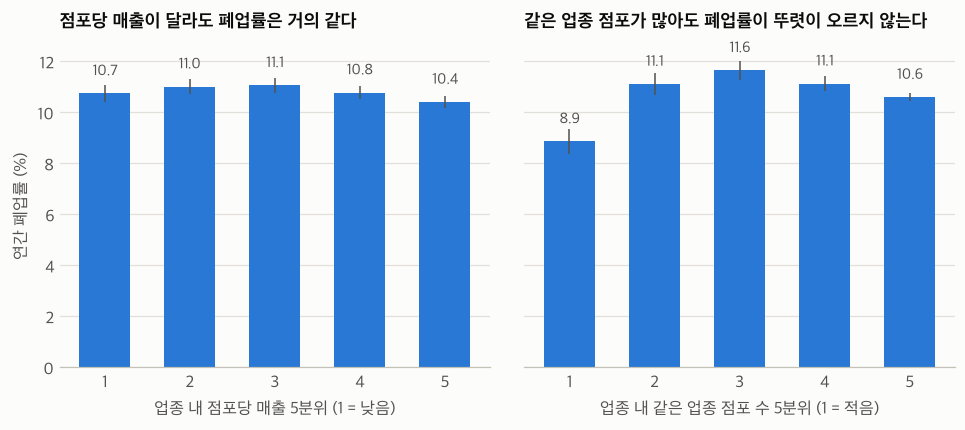

점포당 매출 2배: 폐업률 0.980배 (95% CI 0.969~0.991)
같은 업종 점포 수 2배: 폐업률 1.004배 (95% CI 0.990~1.019)
유동인구 2배: 폐업률 1.023배 (95% CI 1.005~1.041)


In [19]:
qcell = cell[cell["매출분기수"] == 4].copy()
qcell["매출5분위"] = np.ceil(qcell.groupby("업종코드")["점포당월매출"].rank(pct=True) * 5).astype(int)
qcell["경쟁5분위"] = np.ceil(qcell.groupby("업종코드")["평균점포수"].rank(pct=True) * 5).astype(int)


def rate_by(col):
    g = qcell.groupby(col).agg(폐업=("폐업수", "sum"), 개업=("개업수", "sum"), 점포=("평균점포수", "sum"))
    g["폐업률"] = g["폐업"] / g["점포"] * 100
    g["개업률"] = g["개업"] / g["점포"] * 100
    g["오차"] = 1.96 * np.sqrt(g["폐업"]) / g["점포"] * 100
    return g


by_sales, by_comp = rate_by("매출5분위"), rate_by("경쟁5분위")
display(by_sales.round(2)); display(by_comp.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, g, title, xlab in [
    (axes[0], by_sales, "점포당 매출이 달라도 폐업률은 거의 같다", "업종 내 점포당 매출 5분위 (1 = 낮음)"),
    (axes[1], by_comp, "같은 업종 점포가 많아도 폐업률이 뚜렷이 오르지 않는다", "업종 내 같은 업종 점포 수 5분위 (1 = 적음)"),
]:
    ax.bar(g.index, g["폐업률"], width=0.6, color=PAL["s1"])
    ax.errorbar(g.index, g["폐업률"], yerr=g["오차"], fmt="none", ecolor=PAL["ink2"], elinewidth=1, capsize=0)
    for i, v in zip(g.index, g["폐업률"]):
        ax.text(i, v + 0.7, f"{v:.1f}", ha="center", color=PAL["ink2"], fontsize=10)
    ax.set_xlabel(xlab)
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y")
    ax.spines["left"].set_visible(False)
axes[0].set_ylabel("연간 폐업률 (%)")
save(fig, "15_closure_quintile")

glm_d = reg.assign(ln_index=np.log(reg["업종내지수"]), 폐업=reg["폐업수"])
glm = smf.glm("폐업 ~ ln_index + ln_store + ln_flow + C(trdar_type) + C(industry)", data=glm_d, family=sm.families.Poisson(),
              offset=np.log(glm_d["평균점포수"])).fit(cov_type="cluster", cov_kwds={"groups": glm_d["group_id"]})
for term, label in [("ln_index", "점포당 매출 2배"), ("ln_store", "같은 업종 점포 수 2배"), ("ln_flow", "유동인구 2배")]:
    b = glm.params[term]; lo, hi = glm.conf_int().loc[term]
    print(f"{label}: 폐업률 {np.exp(b * np.log(2)):.3f}배 (95% CI {np.exp(lo * np.log(2)):.3f}~{np.exp(hi * np.log(2)):.3f})")

**결과**

- 점포당 매출 5분위별 폐업률은 10.7, 11.0, 11.1, 10.8, 10.4%로 거의 평평합니다.
- 경쟁 5분위는 1분위만 8.9%로 낮고 나머지는 10.6~11.6%입니다. 점포가 많을수록 오르는 모습이 아닙니다.
- 회귀로 보면 점포당 매출 2배일 때 폐업률 0.980배, 같은 업종 점포 2배일 때 1.004배(95% 구간 0.990~1.019), 유동인구 2배일 때 1.023배입니다. 통계적으로 구분되더라도 크기가 작습니다.

**해석**: 업종 안에서 보면 매출이나 경쟁으로 그 칸의 폐업을 거의 설명하지 못합니다. 같은 해의 값이라 시간 순서도 알 수 없습니다. 매출 점수와 안정성 점수는 서로 다른 정보를 담고 있다고 볼 수도 있고, 다음 절처럼 폐업률에 잡음이 많아서일 수도 있습니다.

### 5.5 지표를 믿을 수 있나: 상반기와 하반기 비교

**질문**: 어떤 칸의 값이 그 칸의 특성이라면 상반기와 하반기 값이 비슷해야 합니다. 얼마나 이어지나요?
**방법**: 칸마다 2025년 상반기와 하반기 값을 따로 구해 상관을 봅니다. 개·폐업은 업종 평균으로 기대한 건수와의 차이를 표준화해서 비교합니다. 비율을 그대로 쓰면 폐업 0건 칸이 많아 상관이 부풀려집니다. 점포 수 구간별로 나누고, 이어서 상권 단위로 묶어서도 봅니다.

,칸수,폐업률,개업률,점포당 매출,매출 칸수
구간,,,,,
3~9개,"24,528.00",0.01,0.06,0.93,"12,742.00"
10~19개,"5,613.00",0.03,0.11,0.94,"4,053.00"
20~49개,"2,911.00",0.10,0.15,0.95,"2,233.00"
50개 이상,"1,087.00",0.26,0.43,0.95,835.00


상권 단위로 묶은 반기 상관 (업종 구성 보정)


,상권수,폐업률,개업률
구간,,,
100개 미만,584.00,0.10,0.04
100~299개,667.00,0.20,0.21
300개 이상,393.00,0.41,0.61


전체 상권 폐업 상관 0.256, 개업 상관 0.323


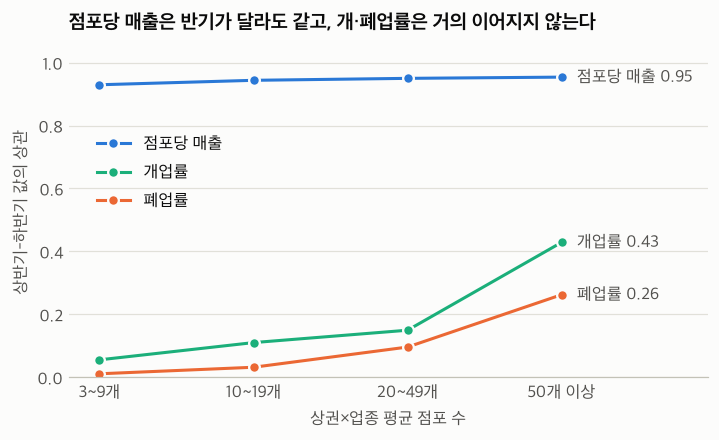

In [20]:
half = panel[panel["상권구분"] != "관광특구"].copy()
half["반기"] = np.where(half["분기"].isin(["20251", "20252"]), "H1", "H2")
h = (half.groupby(["상권코드", "업종코드", "반기"])
     .agg(폐업=("폐업수", "sum"), 개업=("개업수", "sum"), 점포=("점포수", "sum"), 매출=("매출", "sum"), 점포_매출=("점포수_매출분기", "sum"), 분기수=("매출", "count"))
     .unstack("반기"))
h = h[(h[("점포", "H1")] > 0) & (h[("점포", "H2")] > 0)]
codes = h.index.get_level_values("업종코드")


def standardized(col, half_name):
    """업종 평균으로 기대한 건수와의 차이를 포아송 표준편차로 나눈다. 점포가 적은 칸도 같은 잣대로 본다."""
    stock = h[("점포", half_name)] / 2
    rate = h[(col, half_name)].groupby(codes).transform("sum") / stock.groupby(codes).transform("sum")
    expected = stock * rate
    return (h[(col, half_name)] - expected) / np.sqrt(expected)


def log_sales(half_name):
    value = np.log(h[("매출", half_name)] / h[("점포_매출", half_name)])
    return value - value.groupby(codes).transform("mean")


frame = pd.DataFrame({
    "폐업1": standardized("폐업", "H1"), "폐업2": standardized("폐업", "H2"),
    "개업1": standardized("개업", "H1"), "개업2": standardized("개업", "H2"),
    "평균점포": (h[("점포", "H1")] + h[("점포", "H2")]) / 4,
    "4분기매출": (h[("분기수", "H1")] == 2) & (h[("분기수", "H2")] == 2),
})
frame["매출1"] = log_sales("H1").where(frame["4분기매출"])
frame["매출2"] = log_sales("H2").where(frame["4분기매출"])
frame["구간"] = pd.cut(frame["평균점포"], [3, 10, 20, 50, np.inf], right=False, labels=["3~9개", "10~19개", "20~49개", "50개 이상"])
reliability = frame.dropna(subset=["구간"]).groupby("구간", observed=True).apply(lambda d: pd.Series({
    "칸수": len(d), "폐업률": d["폐업1"].corr(d["폐업2"]), "개업률": d["개업1"].corr(d["개업2"]),
    "점포당 매출": d["매출1"].corr(d["매출2"]), "매출 칸수": d["매출1"].notna().sum(),
}), include_groups=False)
display(reliability.round(3))


def trdar_z(col, half_name):
    """상권 안의 업종을 모두 합쳐 실제 건수와 기대 건수의 차이를 표준화한다."""
    stock = h[("점포", half_name)] / 2
    rate = h[(col, half_name)].groupby(codes).transform("sum") / stock.groupby(codes).transform("sum")
    g = pd.DataFrame({"obs": h[(col, half_name)], "exp": stock * rate}).groupby(level="상권코드").sum()
    return (g["obs"] - g["exp"]) / np.sqrt(g["exp"])


trdar_rel = pd.DataFrame({"폐업1": trdar_z("폐업", "H1"), "폐업2": trdar_z("폐업", "H2"), "개업1": trdar_z("개업", "H1"), "개업2": trdar_z("개업", "H2")})
trdar_rel["평균점포"] = tr["평균점포수"].reindex(trdar_rel.index)
trdar_rel["구간"] = pd.cut(trdar_rel["평균점포"], [0, 100, 300, np.inf], labels=["100개 미만", "100~299개", "300개 이상"])
trdar_table = trdar_rel.groupby("구간", observed=True).apply(lambda d: pd.Series({
    "상권수": len(d), "폐업률": d["폐업1"].corr(d["폐업2"]), "개업률": d["개업1"].corr(d["개업2"])}), include_groups=False)
print("상권 단위로 묶은 반기 상관 (업종 구성 보정)")
display(trdar_table.round(3))
print(f"전체 상권 폐업 상관 {trdar_rel['폐업1'].corr(trdar_rel['폐업2']):.3f}, 개업 상관 {trdar_rel['개업1'].corr(trdar_rel['개업2']):.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.9))
x = np.arange(len(reliability))
for name, color in [("점포당 매출", PAL["s1"]), ("개업률", PAL["s3"]), ("폐업률", PAL["s2"])]:
    ax.plot(x, reliability[name], color=color, linewidth=2, marker="o", markersize=7, markeredgecolor=PAL["surface"], markeredgewidth=1.5, label=name)
    ax.text(len(x) - 1 + 0.1, reliability[name].iloc[-1], f"{name} {reliability[name].iloc[-1]:.2f}", va="center", color=PAL["ink2"])
ax.set_xticks(x, reliability.index)
ax.set_xlim(-0.2, len(x) - 1 + 0.95)
ax.set_ylim(0, 1.05)
ax.set_xlabel("상권×업종 평균 점포 수")
ax.set_ylabel("상반기-하반기 값의 상관")
ax.grid(axis="y")
ax.spines["left"].set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.62))
ax.set_title("점포당 매출은 반기가 달라도 같고, 개·폐업률은 거의 이어지지 않는다")
save(fig, "16_half_year_reliability")

**결과**

| 단위 | 구간 | 폐업률 | 개업률 | 점포당 매출 |
|---|---|---|---|---|
| 상권×업종 칸 | 3~9개 | 0.01 | 0.06 | 0.93 |
| | 10~19개 | 0.03 | 0.11 | 0.94 |
| | 20~49개 | 0.10 | 0.15 | 0.95 |
| | 50개 이상 | 0.26 | 0.43 | 0.95 |
| 상권 전체 | 100개 미만 | 0.10 | 0.04 | |
| | 100~299개 | 0.20 | 0.21 | |
| | 300개 이상 | 0.41 | 0.61 | |

- **점포당 매출은 믿을 만합니다.** 어떤 크기의 칸이든 0.93 이상입니다. 다만 추정치라 반기 사이가 비슷하게 만들어졌을 가능성은 남습니다.
- **칸 단위 폐업률은 우연과 구별하기 어렵습니다.** 점포 20개 미만이면 상반기 폐업률이 하반기를 거의 말해 주지 못합니다. 칸의 대부분이 여기 속합니다.
- 상권 단위로 묶으면 나아져서 점포 300개 이상 상권은 0.41입니다. 작은 상권은 묶어도 약합니다.

**제안**: 안정성 점수를 상권×업종 칸의 폐업률로 만들지 않습니다. 상권 단위 값을 쓰고, 작은 상권은 축소 추정을 적용합니다. 2024년 자료를 더하면 기간이 두 배가 되어 더 나아질 것으로 기대합니다.

## 6. 공간 패턴

계획서 시각화 1번(상권별 업종 분포 지도)입니다. 세 지도 모두 관광특구를 뺐고, 옅은 회색 배경은 S01 상가 분포입니다.

- **특화 업종군**: 서울 평균과 비교해 비중이 가장 높은 업종군입니다. 서비스·소매가 외식보다 원래 많기 때문에 단순 최다 업종을 쓰면 지도가 한 색으로 칠해집니다.
- **매출 지수**: 파란색이 높습니다.
- **폐업비**: 업종 구성으로 기대한 폐업 수 대비 실제 폐업 수입니다. 빨간색이 많습니다.

서울 평균 업종군 비중: {'서비스': 34.7, '소매': 39.2, '외식': 26.1}
{'서비스': 671, '외식': 553, '소매': 420}


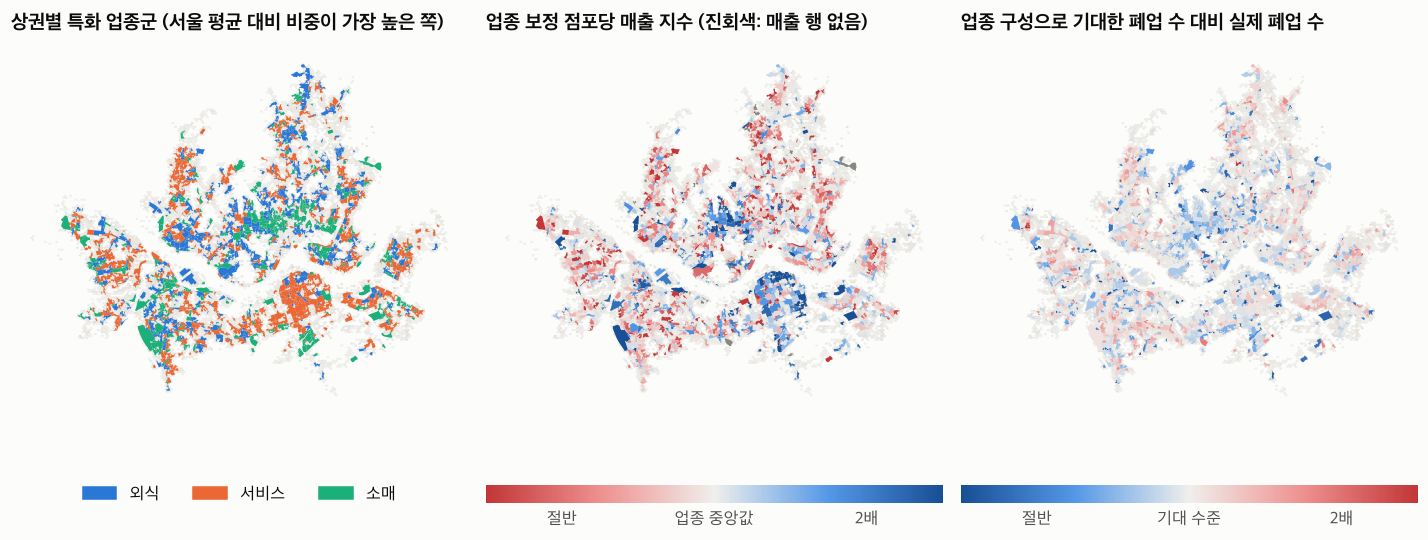

,상권수,연매출_조,평균점포수,폐업수,매출지수_중앙값,연간폐업률,폐업비
자치구,,,,,,,
중구,66,5.36,"36,204.50",2980,1.51,8.23,0.85
강남구,102,10.75,"52,985.75",5041,1.49,9.51,0.97
서초구,74,6.06,"36,407.50",2981,1.27,8.19,0.89
용산구,56,4.30,"16,133.75",1455,1.13,9.02,0.87
종로구,73,4.11,"22,983.25",1896,1.11,8.25,0.84


,상권수,연매출_조,평균점포수,폐업수,매출지수_중앙값,연간폐업률,폐업비
자치구,,,,,,,
광진구,62,2.12,"15,867.50",1813,0.75,11.43,1.07
관악구,74,1.74,"14,529.75",1847,0.74,12.71,1.15
은평구,68,1.43,"13,226.50",1561,0.73,11.80,1.10
중랑구,61,1.43,"12,167.00",1390,0.72,11.42,1.05
강북구,63,1.39,"9,657.75",1224,0.68,12.67,1.15


자치구 단위 Spearman: 매출지수-폐업비 -0.61, 폐업비 범위 0.84~1.23
외식 특화 상권 비중 상위 자치구: {'노원구': 52.0, '용산구': 52.0, '강북구': 49.0}
서비스 특화 상권 비중 상위 자치구: {'강남구': 68.0, '은평구': 60.0, '양천구': 59.0}
소매 특화 상권 비중 상위 자치구: {'중구': 61.0, '종로구': 44.0, '동대문구': 42.0}
상권 단위 매출지수 vs 폐업비 Spearman: -0.13


In [21]:
map_df = k03[k03["상권구분"] != "관광특구"].merge(tr[["매출지수", "연간폐업률", "평균점포수"]].reset_index(), on="상권코드", how="left")
closure_pool = cell.groupby("상권코드").agg(폐업=("폐업수", "sum"), 기대=("평균점포수", "sum"))
mu_tr = rate_cell.assign(mu=mu).groupby("상권코드")["mu"].sum().rename("기대폐업")
closure_pool = closure_pool.join(mu_tr)
closure_pool["폐업비"] = closure_pool["폐업"] / closure_pool["기대폐업"]
map_df = map_df.merge(closure_pool[["폐업비"]].reset_index(), on="상권코드", how="left")

q4_core = k2[k2["분기"] == "20254"]
grp_share = q4_core.pivot_table(index="상권코드", columns="업종군", values="점포수", aggfunc="sum").fillna(0)
grp_share = grp_share.div(grp_share.sum(axis=1), axis=0)
city = q4_core.groupby("업종군")["점포수"].sum() / q4_core["점포수"].sum()
lq = grp_share / city
map_df = map_df.merge(lq.idxmax(axis=1).rename("특화업종군").reset_index(), on="상권코드", how="left")
print("서울 평균 업종군 비중:", (city * 100).round(1).to_dict())
print(map_df["특화업종군"].value_counts().to_dict())

xy = np.c_[pts.geometry.x, pts.geometry.y]
fig = plt.figure(figsize=(16.5, 6.1))
gs = fig.add_gridspec(2, 3, height_ratios=[26, 1], hspace=0.05, wspace=0.04)
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
legend_axes = [fig.add_subplot(gs[1, i]) for i in range(3)]
for ax in axes:
    ax.hexbin(xy[:, 0], xy[:, 1], gridsize=150, bins="log", mincnt=1, cmap=LinearSegmentedColormap.from_list("base", [PAL["neutral"], "#dcdad2"]), linewidths=0)
    ax.set_aspect("equal"); ax.set_axis_off()

for name, color in GROUP_COLOR.items():
    map_df[map_df["특화업종군"] == name].plot(ax=axes[0], color=color, linewidth=0)
legend_axes[0].set_axis_off()
legend_axes[0].legend(handles=[Patch(color=c, label=n) for n, c in GROUP_COLOR.items()], loc="center", ncol=3)
axes[0].set_title("상권별 특화 업종군 (서울 평균 대비 비중이 가장 높은 쪽)", loc="left")

v = np.log2(map_df["매출지수"])
valid = map_df[v.notna()]
norm = TwoSlopeNorm(vcenter=0, vmin=-1.5, vmax=1.5)
valid.plot(ax=axes[1], column=np.log2(valid["매출지수"]), cmap=DIVERGE.reversed(), norm=norm, linewidth=0)
map_df[v.isna()].plot(ax=axes[1], color=PAL["muted"], linewidth=0)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=DIVERGE.reversed()), cax=legend_axes[1], orientation="horizontal", ticks=[-1, 0, 1])
cb.ax.set_xticklabels(["절반", "업종 중앙값", "2배"]); cb.outline.set_visible(False)
axes[1].set_title("업종 보정 점포당 매출 지수 (진회색: 매출 행 없음)", loc="left")

v2 = np.log2(map_df["폐업비"].clip(lower=0.25, upper=4))
norm2 = TwoSlopeNorm(vcenter=0, vmin=-1.5, vmax=1.5)
map_df.plot(ax=axes[2], column=v2, cmap=DIVERGE, norm=norm2, linewidth=0, missing_kwds={"color": PAL["muted"]})
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm2, cmap=DIVERGE), cax=legend_axes[2], orientation="horizontal", ticks=[-1, 0, 1])
cb.ax.set_xticklabels(["절반", "기대 수준", "2배"]); cb.outline.set_visible(False)
axes[2].set_title("업종 구성으로 기대한 폐업 수 대비 실제 폐업 수", loc="left")
save(fig, "17_maps")

gu = tr.reset_index().groupby("자치구").agg(상권수=("상권코드", "size"), 연매출_조=("연매출", lambda s: s.sum() / 1e12), 평균점포수=("평균점포수", "sum"), 폐업수=("폐업수", "sum"), 매출지수_중앙값=("매출지수", "median"))
gu["연간폐업률"] = gu["폐업수"] / gu["평균점포수"] * 100
gu["폐업비"] = tr.join(closure_pool[["폐업", "기대폐업"]]).groupby("자치구").apply(lambda d: d["폐업"].sum() / d["기대폐업"].sum(), include_groups=False)
gu = gu.sort_values("매출지수_중앙값", ascending=False)
gu.round(3).to_csv(TAB / "gu_summary.csv", encoding="utf-8-sig")
display(gu.head(5).round(2)); display(gu.tail(5).round(2))
print(f"자치구 단위 Spearman: 매출지수-폐업비 {stats.spearmanr(gu['매출지수_중앙값'], gu['폐업비'])[0]:.2f}, 폐업비 범위 {gu['폐업비'].min():.2f}~{gu['폐업비'].max():.2f}")
spec = pd.crosstab(map_df["자치구"], map_df["특화업종군"], normalize="index")
for name in ["외식", "서비스", "소매"]:
    print(name, "특화 상권 비중 상위 자치구:", (spec[name].nlargest(3) * 100).round(0).to_dict())
print(f"상권 단위 매출지수 vs 폐업비 Spearman: {stats.spearmanr(*map_df[['매출지수', '폐업비']].dropna().values.T)[0]:.2f}")

**결과**

- 특화 업종군에는 지역 차이가 있습니다. 소매 특화 상권은 중구(61%), 종로구(44%), 동대문구(42%)에 많습니다. 서비스 특화는 강남구(68%)가 가장 높습니다.
- 매출 지수는 중구(1.51), 강남구(1.49), 서초구(1.27)가 높고 강북구(0.68), 중랑구(0.72), 은평구(0.73)가 낮습니다. 강남·도심에 진한 파란색이 모입니다.
- 폐업비는 자치구 단위로 0.84~1.23입니다. 종로구(0.84), 중구(0.85)가 낮고 강서구(1.23), 관악구(1.15)는 기대보다 많습니다.
- **단위에 따라 답이 달라집니다.** 매출 지수와 폐업비의 Spearman은 자치구 단위 -0.61, 상권 단위 -0.13입니다. 칸 단위에서는 5.4처럼 거의 없습니다. 작은 단위에서는 잡음에 묻혀 있던 관계가 큰 단위로 묶으면 드러나는 것으로 보입니다. 다만 자치구는 25개뿐이고, 큰 단위의 관계를 개별 점포에 그대로 적용할 수는 없습니다.

자치구 표는 `tables/gu_summary.csv`에 있습니다. 상권의 자치구는 K03의 대표 자치구입니다.

## 7. 다음 단계에 넘기는 제안

### 계획서의 결정 필요 사항

| 계획서 7장 | 제안 | 근거 |
|---|---|---|
| 1. 분석 기간 | **K01·K02의 2024년 자료를 추가합니다** | 성장률을 계산할 수 있고, 관측 기간이 늘어 폐업률 신뢰도 문제(5.5)도 줄일 수 있습니다 |
| 2. 스냅숏 정렬 | S01을 2025Q4에 맞춥니다 | 상권별 점포 수 순위가 Spearman 0.97로 일치합니다 (1.5) |
| 3. 업종 매핑 | 서울 서비스업종 100개를 기준으로 삼고 S01은 보조로 씁니다 | 매출·개폐업이 이 체계이고, 이름 매핑은 업종에 따라 약합니다 (1.5) |

### 새로 결정할 사항

| # | 사항 | 제안 |
|---|---|---|
| 1 | 점포 0~2개 칸을 추천에 어떻게 넣을지 | 결측으로 유지하고 "매출 미공개"로 표시합니다. 점수를 임의로 채우지 않습니다 |
| 2 | K05~K07의 시점 문제 | 고정 속성으로 쓰고 실제 기준 시점을 명시합니다. 원인은 서울신용보증재단 데이터분석팀(02-2174-5075)에 문의합니다 |
| 3 | 전자상거래업, 부동산중개업 | 전자상거래업은 입지와 무관해 보여 추천에서 제외합니다. 부동산중개업은 매출 칸이 5.9%라 매출 점수를 낼 수 없습니다 |

### STEP별 처리 제안

| 단계 | 처리 | 근거 |
|---|---|---|
| STEP 2 | 서울 합계·순위에서 관광특구 제외, 겹침 없는 1,644개 상권 기준 | 1.3 |
| STEP 2 | K01과 K02는 K02 기준 left join. 매출 없는 칸을 0으로 채우지 않음 | 1.1 |
| STEP 2 | 폐업률은 `clsbiz_rt` 대신 건수로 재계산. 점포 0개 행 포함 | 1.4 |
| STEP 2 | K05~K07은 분기 패널에 반복 결합하지 않음 | 1.2 |
| STEP 2 | K03 폴리곤 6개 `make_valid()` 적용. `RELM_AR`은 ㎡ | 0장 |
| STEP 3 | 매출 변수는 업종 내 지수나 업종 내 백분위. 원값 합계 사용 금지 | 2.2 |
| STEP 3 | 변동성 변수를 쓴다면 4개 분기 동일 값 293칸 제외 | 1.4 |
| STEP 3 | 수요 변수는 유동·직장·상주를 분리. 규모 지표 중복 주의 | 5.2 |
| STEP 4 | 경쟁 위험은 점포 수 단독 감점 금지. 수요 대비 공급으로 재설계 | 5.3, 5.4 |
| STEP 4 | 안정성은 상권 단위에 축소 추정 적용, 가중치는 신뢰도에 맞춰 낮게 시작 | 4.2, 5.5 |
| STEP 5 | 고객층 적합성(시간대·연령) 변수를 희망 업종과 연결 | 3장 |

### 계획서 STEP 6 시각화 진행 상태

| # | 시각화 | 상태 |
|---|---|---|
| 1 | 상권별 업종 분포 지도 | 완료 (그림 17) |
| 2 | 상권별 추정매출 히트맵 | 완료 (그림 6) |
| 3 | 업종별 점포 밀집도 | 표로 완료 (4.1) |
| 4 | 매출 성장률과 폐업률 | **불가**. 2024년 자료 필요. 대신 매출 수준과 폐업률을 확인 (그림 15) |
| 5 | 상권별 집객시설 구성 | 표로 완료 (5.2). 값이 고정되어 있음 |
| 6~7 | 점수 레이더, 금융 MBTI 비교 | STEP 4~5 결과 필요 |

## 8. 한계

- 2025년 1개년입니다. 성장률, 계절성, 지속성은 판단할 수 없습니다.
- 추정매출은 카드사 자료 기반의 추정치입니다. 실제 매출이 아니며, 카드 외 결제가 많은 업종은 덜 잡힐 수 있습니다. 이 부분은 확인하지 못했습니다.
- 매출 분석은 점포 3개 이상이면서 매출 행이 있는 칸만 대상입니다. 작은 칸에는 그대로 일반화할 수 없습니다.
- 임대료, 권리금 같은 비용과 이익 정보가 없습니다. 매출이 높아도 이익이 높다는 뜻은 아닙니다.
- 이 노트북의 모든 관계는 상관입니다. 원인과 결과를 말하려면 시간 순서가 있는 여러 해 자료가 필요합니다.